# CIFAR-10 Mask Transfer

VGG11 with one Source mask (seed **111**) and Target initializations **666, 888, 999**.
Compare **Naive, Magnitude, Random, Gradient**, each for **5,000 updates**.
Run cells in order, locally or on a Colab GPU. Google Drive is not required.


## 1. Environment
Use Colab's Torch/Torchvision or a compatible local installation.


In [1]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import sys
import importlib.util
import subprocess

INSTALL_MISSING_HELPERS = True
helper_packages = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "tqdm": "tqdm", "psutil": "psutil"}
missing = [package for module, package in helper_packages.items() if importlib.util.find_spec(module) is None]
if missing:
    if not INSTALL_MISSING_HELPERS:
        raise ImportError(f"Install these notebook dependencies first: {missing}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

import contextlib
import gc
import hashlib
import io
import json
import math
import platform
import random
import shutil
import time
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import torch.nn.utils.prune as prune
    import torchvision
    from torch.utils.data import DataLoader, Subset
    from torchvision import datasets, transforms
except (ImportError, RuntimeError, OSError) as exc:
    raise RuntimeError("A compatible Torch/Torchvision installation is required. "
                       "Use the Colab runtime's supplied pair, or install a matched pair locally.") from exc
from tqdm.auto import tqdm
from IPython.display import display

try:
    IS_COLAB = importlib.util.find_spec("google.colab") is not None
except (ImportError, ValueError):
    IS_COLAB = False
print("Environment:", "Colab" if IS_COLAB else "local")
print("Python:", platform.python_version(), "Torch:", torch.__version__, "Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())


Environment: Colab
Python: 3.13.16 Torch: 2.11.0+cu130 Torchvision: 0.26.0+cu130
CUDA available: True


## 2. Storage
Outputs use the local study folder or `/content/data_transfer_learning` on Colab.
Download Colab reports/checkpoints before the runtime is deleted. Partial training is not resumed.


In [2]:
OUTPUT_ROOT = None  # Colab default: /content/data_transfer_learning; local default: project folder.
DATA_ROOT_OVERRIDE = None  # Existing cache root, cifar-10-batches-py folder, or official tar.gz path.
ALLOW_CIFAR10_DOWNLOAD = True  # Used ONLY if no verified cache/archive can be found; False forces offline reuse.

def resolve_storage_paths(cwd, is_colab, output_override=None, data_override=None):
    cwd = Path(cwd).expanduser().resolve()
    local_root = (Path("/content/data_transfer_learning") if is_colab else
                  cwd if cwd.name == "data_transfer_learning" else cwd / "data_transfer_learning")
    output = Path(output_override).expanduser().resolve() if output_override else local_root
    data = (Path(data_override).expanduser().resolve() if data_override else
            local_root / "data")
    return output, data, local_root / ".staging"

def probe_writable(directory):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    probe = directory / f".write_probe_{uuid.uuid4().hex}"
    token = uuid.uuid4().hex.encode("ascii")
    with probe.open("xb") as stream:
        stream.write(token)
        stream.flush()
    if probe.read_bytes() != token:
        raise OSError(f"Storage readback failed at {directory}.")
    probe.unlink()

STUDY_ROOT, DATA_ROOT, LOCAL_STAGING_ROOT = resolve_storage_paths(
    Path.cwd(), IS_COLAB, OUTPUT_ROOT, DATA_ROOT_OVERRIDE)
probe_writable(STUDY_ROOT)
probe_writable(LOCAL_STAGING_ROOT)
STORAGE = {"backend": "colab_runtime_disk" if IS_COLAB else "local_disk",
           "use_google_drive": False, "study_root": str(STUDY_ROOT), "data_root": str(DATA_ROOT),
           "local_staging_root": str(LOCAL_STAGING_ROOT), "write_read_probe_passed": True}

def ensure_storage_ready():
    if not STUDY_ROOT.is_dir():
        raise RuntimeError(f"Output directory disappeared: {STUDY_ROOT}")

def storage_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def publish_local_file(local_path, destination):
    ensure_storage_ready()
    local_path, destination = Path(local_path), Path(destination)
    if not destination.resolve().is_relative_to(STUDY_ROOT.resolve()):
        raise ValueError("Artifacts must be saved inside the selected study output root.")
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_name(f".{destination.name}.{uuid.uuid4().hex}.part")
    expected_size = local_path.stat().st_size
    expected_hash = storage_sha256(local_path)
    shutil.copyfile(local_path, temporary)
    if temporary.stat().st_size != expected_size or storage_sha256(temporary) != expected_hash:
        raise OSError(f"Artifact verification failed; local file remains at {local_path}")
    ensure_storage_ready()
    temporary.replace(destination)
    return {"path": str(destination), "bytes": expected_size, "sha256": expected_hash}

def write_text_verified(path, content):
    ensure_storage_ready()
    path = Path(path)
    if not path.resolve().is_relative_to(STUDY_ROOT.resolve()):
        raise ValueError("Reports must stay inside the selected study output root.")
    temporary = path.with_name(f".{path.name}.{uuid.uuid4().hex}.tmp")
    payload = content.encode("utf-8")
    with temporary.open("xb") as stream:
        stream.write(payload)
        stream.flush()
    if temporary.read_bytes() != payload:
        raise OSError(f"Text readback failed: {temporary}")
    ensure_storage_ready()
    temporary.replace(path)

def write_csv(frame, path, index=True):
    write_text_verified(path, frame.to_csv(index=index))

def save_torch_verified(payload, destination):
    ensure_storage_ready()
    local_path = LOCAL_STAGING_ROOT / f"checkpoint_{uuid.uuid4().hex}.pt"
    torch.save(payload, local_path)
    published = publish_local_file(local_path, destination)
    local_path.unlink()
    return published

def save_figure_verified(figure, destination, **kwargs):
    local_path = LOCAL_STAGING_ROOT / f"figure_{uuid.uuid4().hex}{Path(destination).suffix}"
    figure.savefig(local_path, **kwargs)
    published = publish_local_file(local_path, destination)
    local_path.unlink()
    return published

print("Storage preflight: PASS")
print("Training outputs:", STUDY_ROOT)
print("Preferred CIFAR cache (existing caches are detected before loading):", DATA_ROOT)
print("Local checkpoint/ZIP staging:", LOCAL_STAGING_ROOT)
print("Google Drive: not used; no mounting or authorization.")


Storage preflight: PASS
Training outputs: /content/data_transfer_learning
Preferred CIFAR cache (existing caches are detected before loading): /content/data_transfer_learning/data
Local checkpoint/ZIP staging: /content/data_transfer_learning/.staging
Google Drive: not used; no mounting or authorization.


## 3. Configuration
Default: **5,000 updates**, allocated **5:5:1:1:1:1** across growth and pruning phases.
Growth reaches **30%, 40%**; global-L1 pruning returns to **20%** density.
Edit budgets, paths and runtime options below.


In [3]:
PROTOCOL = "mask_only_v6_outer_aligned_group80_20"
TARGET_BUDGET_MODE = "fixed_updates"  # "fixed_updates" (5,000 each) or "outer_epochs" (outer stage epochs).
FIXED_TARGET_UPDATES = 5000  # Optimizer updates, not epochs.
SOURCE_SEED = 111
TARGET_SEEDS = [666, 888, 999]
TARGET_TRAIN_SEED = 222
TARGET_SAMPLER_SEED = 333
TOPOLOGY_SEED = 444
SPLIT_SEED = 20261030
METHODS = ["naive", "magnitude", "random", "gradient"]
DOMAIN_SIZE, TRAIN_SIZE, VAL_SIZE, DOMAIN_TEST_SIZE = 25000, 22500, 2500, 5000
VALIDATION_FRACTION = 0.10
GROUP_A_IDS, GROUP_B_IDS = (0, 1, 2, 3, 4), (5, 6, 7, 8, 9)
GROUP_A_FRACTIONS = {"A": 0.80, "B": 0.20}
BATCH_SIZE, EVAL_BATCH_SIZE, EVAL_EVERY = 128, 256, 10
FINAL_DENSITY, PEAK_DENSITY = 0.20, 0.40
DEVICE_REQUEST = "auto"
TARGET_BACKEND = "auto"  # "auto", "grouped", or "sequential".
SAVE_FINAL_MODELS = True
SOURCE_MASK_FILE = None  # Only a matching v6 source_mask_only.pt can be reused.
OUTER_CONFIG = {'model_type': 'VGG11', 'epochs': 5, 'batch_size': 128, 'model_b_epochs': 1, 'sparse_epochs': 15, 'num_workers': 8, 'init_weights': True, 'project': 'cifar10_vgg11_by_gradient', 'entity': None, 'dataset': 'cifar10', 'dataset_root': {'cifar10': './dataset/cifar10', 'cifar100': './dataset/cifar100'}, 'optimizer': {'type': 'SGD', 'sparse_lr': 0.02, 'lr': 0.08, 'momentum': 0.9, 'weight_decay': 0.0005}, 'pruning': {'sparsity': 0.8, 'prune_perc': 0.2, 'prune_epochs': 10, 'prune_lr': 0.01, 'train_epochs_per_prune': 1, 'tolerance_vgg11': 5e-07, 'tolerance_resnet20': 0.005}, 'progressive': {'target_densities': [0.3, 0.4], 'epochs_per_stage': 5, 'selection': 'gradient', 'growth_seed': 0}, 'device': 'cuda', 'width_multiplier': 1, 'save_path': './res/vgg11/'}
EMBEDDED_UPSTREAM_SHA256 = {'models.py': 'bb4a1ec5d4e907a2e4315d04ff5350eb3e6f465785312ce067d18db27f0be12d', 'progressive.py': '06122880a5cadd9cb189543e6bb0b79e80146415ad90b5ca1bbf04ea20f079b5', 'training.py': '9eddeb83d3071a6768b45d58a821c950a71ec7f05c6852fa13970841341d42b6', 'pruning.py': '6f7b32a6929e3c3203a7bf94f8eb7c13506742d17279576185a98705b9783ef9', 'utils.py': '73cd057fab1f815ebddf9c978285a534521a0cd97618f1ccd6117f3750302a96', 'experiment.py': '6b9eeada1068cb34c731b2c779c69f77ee696ab904744674e0c00c9a5d06cd44', 'loaders.py': '4b10939f21d6d009f3c25658a4a06cfa3d0f69e19722d4110bcbf11928d62338', 'configs/config_cifar10_vgg_1_80.yaml': 'fe3c3212778d2e9061bb1c22e99244d5149794889bb610758e82812abf55fa63'}
assert TARGET_BUDGET_MODE in {"fixed_updates", "outer_epochs"}
assert SOURCE_SEED == 111 and TARGET_SEEDS == [666, 888, 999]
assert OUTER_CONFIG["progressive"]["target_densities"] == [0.3, 0.4]
assert DEVICE_REQUEST in {"auto", "cuda", "cpu"}
assert TARGET_BACKEND in {"auto", "grouped", "sequential"}
if DEVICE_REQUEST == "cuda" and not torch.cuda.is_available():
    raise RuntimeError("CUDA requested but unavailable. Select a GPU runtime.")
DEVICE = torch.device("cuda" if DEVICE_REQUEST == "auto" and torch.cuda.is_available()
                      else "cpu" if DEVICE_REQUEST == "auto" else DEVICE_REQUEST)
if TARGET_BACKEND == "grouped" and DEVICE.type != "cuda":
    raise RuntimeError("Grouped production execution requires a CUDA GPU; use auto or sequential on CPU.")
EFFECTIVE_TARGET_BACKEND = "grouped" if DEVICE.type == "cuda" and TARGET_BACKEND != "sequential" else "sequential"
ensure_storage_ready()
BUDGET_LABEL = f"{FIXED_TARGET_UPDATES}updates_outer_ratio" if TARGET_BUDGET_MODE == "fixed_updates" else "yaml_epochs"
RUN_ID = f"{PROTOCOL}_{TARGET_BUDGET_MODE}_{BUDGET_LABEL}_{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}_{uuid.uuid4().hex[:6]}"
RUN_DIR = STUDY_ROOT / "runs" / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
CONFIG = {"protocol": PROTOCOL, "storage": STORAGE, "outer_config": OUTER_CONFIG,
          "target_budget_mode": TARGET_BUDGET_MODE, "fixed_target_updates": FIXED_TARGET_UPDATES,
          "fixed_phase_policy": "proportional_to_outer_config_epochs",
          "source_seed": SOURCE_SEED, "target_init_seeds": TARGET_SEEDS,
          "target_train_seed": TARGET_TRAIN_SEED, "target_sampler_seed": TARGET_SAMPLER_SEED,
          "topology_seed": TOPOLOGY_SEED, "split_seed": SPLIT_SEED,
          "methods": METHODS, "batch_size": BATCH_SIZE, "train_drop_last": True,
          "target_backend": EFFECTIVE_TARGET_BACKEND, "precision": "float32",
          "source_mask_file": str(SOURCE_MASK_FILE) if SOURCE_MASK_FILE else None,
          "gradient_score": "abs(weight_orig.grad), ordinary outer masked backward; zero inactive scores retained",
          "dormant_policy": "ordinary outer optimizer updates; no restoring weights or clearing momentum",
          "growth_targets": OUTER_CONFIG["progressive"]["target_densities"],
          "pruning": "outer fractional global L1, 20% of remaining until 80% sparsity",
          "optimizer": "new outer trainer optimizer per growth stage; new outer prune optimizer per prune round",
          "scheduler": "outer epoch-wise cosine; each fixed-budget stage may end with a partial data epoch",
          "primary_test_view": "target_test", "test_views": {"target_test": 5000, "source_test": 5000, "balanced_test": 10000},
          "test_endpoint": "fixed final update, no test-best checkpoint",
          "data_rng": "private per-method CPU augmentation and loader generators; probe uses dedicated B training loader"}
ENVIRONMENT = {"python": platform.python_version(), "torch": str(torch.__version__),
               "torchvision": str(torchvision.__version__), "device": str(DEVICE),
               "cuda_runtime": torch.version.cuda, "colab": IS_COLAB,
               "gpu": torch.cuda.get_device_name(DEVICE) if DEVICE.type == "cuda" else None}
def write_json(path, obj):
    write_text_verified(path, json.dumps(obj, indent=2, allow_nan=False))
write_json(RUN_DIR / "config.json", {"run_id": RUN_ID, "config": CONFIG, "environment": ENVIRONMENT})
write_json(RUN_DIR / "embedded_source.json", EMBEDDED_UPSTREAM_SHA256)
write_json(RUN_DIR / "storage_check.json", STORAGE)
print("Run:", RUN_DIR)
print("Source initialization:", SOURCE_SEED, "| B initializations:", TARGET_SEEDS)
print("Target budget mode:", TARGET_BUDGET_MODE, "| backend:", EFFECTIVE_TARGET_BACKEND, "|", DEVICE)
print("Outer defaults: source dense 5 epochs, prune recovery 1 epoch; growth [30%, 40%], 5 epochs/stage.")
if TARGET_BUDGET_MODE == "fixed_updates":
    print("Each B method:", FIXED_TARGET_UPDATES, "updates | evaluations:", 1 + math.ceil(FIXED_TARGET_UPDATES / EVAL_EVERY))
    print("Phase time proportions come from the outer config: growth epochs per stage, then recovery epochs per pruning round.")
if DEVICE.type == "cuda":
    print("GPU:", ENVIRONMENT["gpu"], "| capacity GiB:", round(torch.cuda.get_device_properties(DEVICE).total_memory / 1024**3, 2))


Run: /content/data_transfer_learning/runs/mask_only_v6_outer_aligned_group80_20_fixed_updates_5000updates_outer_ratio_20261101T090212Z_4d5678
Source initialization: 111 | B initializations: [666, 888, 999]
Target budget mode: fixed_updates | backend: grouped | cuda
Outer defaults: source dense 5 epochs, prune recovery 1 epoch; growth [30%, 40%], 5 epochs/stage.
Each B method: 5000 updates | evaluations: 501
Phase time proportions come from the outer config: growth epochs per stage, then recovery epochs per pruning round.
GPU: Tesla T4 | capacity GiB: 14.56


## 4. Model and algorithm
Embedded VGG11 and the outer growth, pruning and training primitives.


In [4]:
"""Standalone outer-pipeline algorithm core for the transfer notebook.

This source fragment is embedded in the notebook. Importing it never trains,
downloads data, or loads a dataset. Copied upstream functions are unmodified.

The outer gradient-growth implementation scores ``weight_orig.grad`` after a
masked forward. Inactive gradients are consequently zero. This behavior is
retained deliberately for algorithm parity, including its tied-score choices.
"""
from __future__ import annotations

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.utils.prune as prune
import torch.optim as optim


cfg = {
    "VGG11": {
        "layers": [64, "M", 128, "M", 256, 256, "M", 512, 512, "M", 512, 512, "M"]
    }
}

class VGG11_nofc(nn.Module):
    def __init__(self, config, vgg_name, num_classes, w=1, init_weights=True):
        super(VGG11_nofc, self).__init__()
        self.config = config
        self.w = w
        self.num_classes = num_classes
        print("the number of classes", self.num_classes)
        self.features = self._make_layers(cfg[vgg_name]["layers"])
        self.classifier = nn.Linear(self.w * 512, self.num_classes)
        if init_weights:
            self._initialize_weights()

    def forward(self, x):
        out = self.features(x)
        out = out.view(out.size(0), -1)
        out = self.classifier(out)
        return out

    def _make_layers(self, cfg):
        layers = []
        in_channels = 1 if self.config["dataset"] == "mnist" else 3
        for x in cfg:
            if x == "M":
                # MNIST's 28x28 input reaches odd spatial sizes before the
                # final VGG pooling layer. Ceil mode keeps those sizes valid.
                layers += [nn.MaxPool2d(kernel_size=2, stride=2, ceil_mode=True)]
            else:
                layers.append(
                    nn.Conv2d(
                        in_channels if in_channels == 3 else self.w * in_channels,
                        self.w * x,
                        kernel_size=3,
                        padding=1,
                    )
                )
                layers.append(nn.ReLU(inplace=True))
                in_channels = x
        layers += [nn.AvgPool2d(kernel_size=1, stride=1)]
        return nn.Sequential(*layers)

    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                print("Initializing with Kaiming Normal", m)
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)

            elif isinstance(m, nn.Linear):
                print("Initializing with Normal", m)
                nn.init.normal_(m.weight, 0, 0.01)
                nn.init.constant_(m.bias, 0)

def eligible_modules(model: nn.Module, model_type: str) -> list[tuple[str, nn.Module]]:
    """Return layers whose weights participate in the global mask."""
    excluded = ()
    if model_type == "ResNet":
        excluded = ("shortcut",)
    elif model_type == "ResNet50":
        excluded = ("shortcut", "downsample")
    elif model_type not in {"VGG11", "LeNet"}:
        raise ValueError(f"Unsupported model type: {model_type}")

    return [
        (name, module)
        for name, module in model.named_modules()
        if isinstance(module, (nn.Conv2d, nn.Linear))
        and not any(part in name for part in excluded)
    ]

def _mask(module: nn.Module) -> torch.Tensor:
    if not hasattr(module, "weight_mask"):
        raise ValueError("All progressive layers must have a weight_mask")
    return module.weight_mask.detach()

def mask_statistics(model: nn.Module, model_type: str) -> tuple[int, int]:
    """Return active and total eligible parameter counts."""
    active = total = 0
    for _, module in eligible_modules(model, model_type):
        mask = _mask(module)
        active += int(mask.count_nonzero().item())
        total += mask.numel()
    return active, total

def snapshot_masks(model: nn.Module, model_type: str) -> dict[str, torch.Tensor]:
    """Return a detached copy of the current eligible-layer masks."""
    return {
        name: _mask(module).bool().clone()
        for name, module in eligible_modules(model, model_type)
    }

def mask_retention_statistics(
    model: nn.Module,
    model_type: str,
    initial_masks: dict[str, torch.Tensor],
    grown_masks: dict[str, torch.Tensor],
) -> dict[str, int | float]:
    """Measure which original and progressively added connections survive.

    ``initial_masks`` is the mask transferred from Model A and ``grown_masks``
    is the mask immediately before the final pruning phase.

    The retention ratios are set intersections:
    ``initial_retention = |initial ∩ final| / |initial|`` and
    ``added_retention = |(grown - initial) ∩ final| / |grown - initial|``.
    """
    final_masks = snapshot_masks(model, model_type)
    names = {name for name, _ in eligible_modules(model, model_type)}
    if set(initial_masks) != names or set(grown_masks) != names:
        raise ValueError("Mask snapshots do not match the model's eligible layers")

    initial = torch.cat([initial_masks[name].reshape(-1) for name in sorted(names)])
    grown = torch.cat([grown_masks[name].reshape(-1) for name in sorted(names)])
    final = torch.cat([final_masks[name].reshape(-1) for name in sorted(names)])
    added = grown & ~initial

    initial_count = int(initial.sum().item())
    added_count = int(added.sum().item())
    return {
        "initial_active": initial_count,
        "added_active": added_count,
        "final_active": int(final.sum().item()),
        "initial_retained": int((initial & final).sum().item()),
        "added_retained": int((added & final).sum().item()),
        "initial_retention": (
            float((initial & final).sum().item() / initial_count)
            if initial_count
            else 1.0
        ),
        "added_retention": (
            float((added & final).sum().item() / added_count) if added_count else 1.0
        ),
    }

def validate_mask_compatibility(
    source_model: nn.Module, target_model: nn.Module, model_type: str
) -> None:
    source_layers = eligible_modules(source_model, model_type)
    target_layers = eligible_modules(target_model, model_type)
    if [name for name, _ in source_layers] != [name for name, _ in target_layers]:
        raise ValueError("Source and target progressive layers do not match")
    for (name_a, source), (name_b, target) in zip(source_layers, target_layers):
        if source.weight.shape != target.weight.shape:
            raise ValueError(
                f"Layer shape mismatch for {name_a}/{name_b}: "
                f"{tuple(source.weight.shape)} != {tuple(target.weight.shape)}"
            )

def _install_masks(
    model: nn.Module, masks: dict[str, torch.Tensor], model_type: str
) -> None:
    """Install masks without discarding the original dense weights."""
    for name, module in eligible_modules(model, model_type):
        if hasattr(module, "weight_mask"):
            module.weight_mask.data.copy_(
                masks[name].to(
                    device=module.weight_mask.device, dtype=module.weight_mask.dtype
                )
            )
        else:
            prune.custom_from_mask(
                module, "weight", masks[name].to(device=module.weight.device)
            )

def transfer_mask(
    source_model: nn.Module, target_model: nn.Module, model_type: str
) -> nn.Module:
    """Apply a source mask to target weights without copying source weights."""
    validate_mask_compatibility(source_model, target_model, model_type)
    masks = {
        name: _mask(source).to(dtype=target.weight.dtype).clone()
        for (name, source), (_, target) in zip(
            eligible_modules(source_model, model_type),
            eligible_modules(target_model, model_type),
        )
    }
    _install_masks(target_model, masks, model_type)
    return target_model

def grow_mask(
    model: nn.Module,
    model_type: str,
    target_density: float,
    selection: str = "magnitude",
    generator: torch.Generator | None = None,
) -> tuple[int, int]:
    """Grow inactive connections until the requested global density is met.

    Growth never removes an active connection. Magnitude selection uses the
    current effective target weights, ``gradient`` uses the absolute
    gradients of the dense weights, and random selection is available for
    controlled ablations.
    """
    if not 0.0 <= target_density <= 1.0:
        raise ValueError("target_density must be between 0 and 1")
    if selection not in {"magnitude", "random", "gradient"}:
        raise ValueError("selection must be 'magnitude', 'random', or 'gradient'")

    layers = eligible_modules(model, model_type)
    if selection == "gradient":
        for _, module in layers:
            weights = getattr(module, "weight_orig", module.weight)
            if weights.grad is None:
                raise ValueError(
                    "gradient selection requires gradients on all progressive layers"
                )

    old_active, total = mask_statistics(model, model_type)
    target_active = int(round(target_density * total))
    if target_active < old_active:
        raise ValueError(
            f"Progressive growth cannot reduce active weights: "
            f"{old_active} -> {target_active}"
        )
    add_count = target_active - old_active
    if add_count == 0:
        return old_active, total

    candidate_indices: list[torch.Tensor] = []
    candidate_scores: list[torch.Tensor] = []
    for name, module in layers:
        mask = _mask(module).bool()
        weights = getattr(module, "weight_orig", module.weight)
        if selection == "gradient":
            scores = weights.grad.detach().abs()
        else:
            scores = weights.detach().abs()
        inactive = ~mask.reshape(-1)
        candidate_indices.append(inactive.nonzero(as_tuple=False).flatten())
        candidate_scores.append(scores.reshape(-1)[inactive])

    candidate_count = sum(indices.numel() for indices in candidate_indices)
    if add_count > candidate_count:
        raise ValueError("Requested density exceeds available inactive weights")

    scores = torch.cat(candidate_scores)
    if selection == "magnitude":
        _, selected = torch.topk(scores, add_count, largest=True, sorted=False)
    elif selection == "random":
        order = torch.randperm(candidate_count, generator=generator)
        selected = order[:add_count].to(device=scores.device)
    else:
        _, selected = torch.topk(scores, add_count, largest=True, sorted=False)

    masks = {name: _mask(module).clone() for name, module in layers}
    offsets = torch.tensor(
        [
            0,
            *torch.cumsum(
                torch.tensor(
                    [indices.numel() for indices in candidate_indices],
                    dtype=torch.long,
                ),
                dim=0,
            ).tolist(),
        ],
        device=scores.device,
    )
    # A candidate at a cumulative boundary belongs to the following layer.
    layer_indices = torch.bucketize(selected, offsets[1:-1], right=True)
    for layer_index, (name, _) in enumerate(layers):
        selected_in_layer = selected[layer_indices == layer_index]
        if selected_in_layer.numel() == 0:
            continue
        local_indices = selected_in_layer - offsets[layer_index]
        flat_mask = masks[name].reshape(-1)
        flat_mask[candidate_indices[layer_index][local_indices]] = 1
    _install_masks(model, masks, model_type)
    return mask_statistics(model, model_type)

def assert_density(
    model: nn.Module, model_type: str, expected_density: float, tolerance: float = 1e-6
) -> None:
    active, total = mask_statistics(model, model_type)
    actual = active / total
    if abs(actual - expected_density) > tolerance:
        raise AssertionError(
            f"Expected density {expected_density:.12f}, got {actual:.12f}"
        )

def evaluate(model, dataloader, device):
    """Evaluate the model on the dataloader, return accuracy and loss. No TTA."""
    loss_fn = nn.CrossEntropyLoss()
    model.eval()
    correct = 0
    total = 0
    test_loss = 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            outputs = model(X)

            pred = outputs.argmax(dim=1)
            correct += (y == pred).sum().item()
            total += y.size(0)
            loss = loss_fn(outputs, y)
            test_loss += loss.item()

    test_accuracy = correct / total
    test_loss /= len(dataloader)
    return test_accuracy * 100, test_loss

def sparse_grad_tolerance(model, tolerance=1):
    for name, param in model.named_parameters():
        if param.grad is not None:
            grad_sparsity = float(torch.sum(param.grad == 0)) / torch.numel(param.grad)
            for name, module in model.named_modules():
                if hasattr(param, 'weight_mask'):
                    mask_sparsity, _, _ = calculate_mask_sparsity(module.weight_mask)
                    assert abs(mask_sparsity - grad_sparsity) <= tolerance, \
                        f"Sparsity mismatch in {name}: mask_sparsity={mask_sparsity}, grad_sparsity={grad_sparsity}"

def calculate_mask_sparsity(weight_mask):
    total_params = torch.numel(weight_mask)
    zero_params = torch.sum(weight_mask == 0).item()
    sparsity = zero_params / total_params
    return sparsity, zero_params, total_params

def calculate_overall_sparsity_from_pth(model):
    total_zero_params = 0
    total_params = 0

    for name, param in model.state_dict().items():
        if 'weight_mask' in name:
            _, zero_params, num_params = calculate_mask_sparsity(param)
            total_zero_params += zero_params
            total_params += num_params

    overall_sparsity = total_zero_params / total_params if total_params > 0 else 0
    return overall_sparsity

def train_epoch(model, dataloader, optimizer, device, sparse=False):

    model.train()
    running_loss = 0
    loss_fn = nn.CrossEntropyLoss()

    for X, y in dataloader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)
        running_loss += loss.item()
        # Backpropagation
        loss.backward()

        if sparse:
            sparse_grad_tolerance(model)
        optimizer.step()

    return running_loss / len(dataloader)

def _compute_progressive_gradients(model, train_dl):
    """Compute one loss gradient for gradient-based mask growth."""
    was_training = model.training
    model.eval()
    model.zero_grad(set_to_none=True)
    inputs, targets = next(iter(train_dl))
    device = next(model.parameters()).device
    loss = torch.nn.CrossEntropyLoss()(model(inputs.to(device)), targets.to(device))
    loss.backward()
    model.train(was_training)


# Aliases distinguish these exact upstream primitives from richer report helpers.
outer_evaluate = evaluate
outer_train_epoch = train_epoch
outer_gradient_probe = _compute_progressive_gradients


def outer_stage_optimizer(model, optimizer_config, sparse=True):
    """Construct a NEW optimizer exactly as training.trainer does per call."""
    optimizer_type = getattr(optim, optimizer_config["type"])
    lr = optimizer_config["sparse_lr"] if sparse else optimizer_config["lr"]
    return optimizer_type(
        model.parameters(),
        lr=lr,
        momentum=optimizer_config["momentum"],
        weight_decay=optimizer_config["weight_decay"],
    )


def outer_stage_training_state(model, optimizer_config, epochs, sparse=True):
    """A fresh optimizer/cosine pair; call scheduler.step() AFTER each epoch."""
    optimizer = outer_stage_optimizer(model, optimizer_config, sparse=sparse)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, epochs, eta_min=0.0
    )
    return optimizer, scheduler


def outer_prune_optimizer(model, optimizer_config, initial_lr):
    """Construct a NEW optimizer exactly as pruning.prune_model does per round.

    Outer pruning only forwards optimizer_config['params'], not the top-level
    momentum/weight_decay keys used by training.trainer. If params is absent,
    SGD's defaults apply (zero momentum and zero weight decay). Do not merge
    the top-level fields here: doing that would change the outer algorithm.
    """
    optimizer_type = getattr(optim, optimizer_config["type"])
    return optimizer_type(
        model.parameters(), lr=initial_lr, **optimizer_config.get("params", {})
    )


def outer_prune_training_state(model, optimizer_config, initial_lr, train_epochs_per_prune):
    """A fresh pruning-round optimizer/cosine pair using upstream semantics."""
    optimizer = outer_prune_optimizer(model, optimizer_config, initial_lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, train_epochs_per_prune, eta_min=0.0
    )
    return optimizer, scheduler


def outer_prune_round(model, target_sparsity=0.8, initial_prune_perc=0.2):
    """Apply one VGG11 pruning.prune_model round with the SAME rounding rule.

    Fractional ``amount`` is passed unchanged to global_unstructured. This
    preserves PyTorch's rounding and tie selection rather than replacing it
    with a custom integer-density target. Existing active values are retained;
    no initialization rewinding, dormant restoration, or momentum edits occur.
    """
    parameters_to_prune = [
        (module, 'weight') for name, module in model.named_modules()
        if isinstance(module, (torch.nn.Conv2d, torch.nn.Linear))
    ]
    current_sparsity = calculate_overall_sparsity_from_pth(model)
    old_active = total = 0
    for _, module in eligible_modules(model, "VGG11"):
        total += module.weight.numel()
        if hasattr(module, "weight_mask"):
            old_active += int(module.weight_mask.count_nonzero().item())
        else:
            old_active += module.weight.numel()
    if current_sparsity < target_sparsity:
        max_additional_sparsity = target_sparsity - current_sparsity
        adjusted_prune_perc = min(
            initial_prune_perc, max_additional_sparsity / (1 - current_sparsity)
        )
    else:
        adjusted_prune_perc = 0
    prune.global_unstructured(
        parameters_to_prune,
        pruning_method=prune.L1Unstructured,
        amount=adjusted_prune_perc,
    )
    active, _ = mask_statistics(model, "VGG11")
    return {
        "action": "prune", "rule": "outer_global_l1",
        "old_active": old_active, "new_active": active,
        "total_weights": total, "density": active / total,
        "sparsity": calculate_overall_sparsity_from_pth(model),
        "adjusted_prune_perc": adjusted_prune_perc,
        "changed_connections": old_active - active,
        "target_sparsity": float(target_sparsity),
    }


def outer_gradient_candidate_diagnostics(model):
    """Observe the SAME inactive weight_orig.grad scores used by grow_mask.

    This diagnostic performs no forward/backward and does not change tensors.
    Zero inactive scores are reported, never rejected or replaced.
    """
    vectors = []
    for _, module in eligible_modules(model, "VGG11"):
        weights = getattr(module, "weight_orig", module.weight)
        if weights.grad is None:
            raise ValueError("Run outer_gradient_probe before gradient growth.")
        inactive = ~module.weight_mask.detach().bool()
        vectors.append(weights.grad.detach().abs()[inactive].reshape(-1))
    scores = torch.cat(vectors)
    return {
        "candidate_count": scores.numel(),
        "candidate_score_mean": float(scores.mean()) if scores.numel() else 0.0,
        "candidate_score_max": float(scores.max()) if scores.numel() else 0.0,
        "candidate_nonzero_fraction": float((scores != 0).float().mean()) if scores.numel() else 0.0,
        "score_definition": "abs(weight_orig.grad) from ordinary masked backward",
        "known_outer_zero_inactive_gradients": True,
    }


## 5. Mask utilities and operation counts
Sparse FLOPs are theoretical; masked PyTorch kernels still perform dense operations.


In [5]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed % (2**32))
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)

def fresh_vgg(seed, initialize=True, device=DEVICE):
    seed_everything(seed)
    with contextlib.redirect_stdout(io.StringIO()):
        model = VGG11_nofc({"dataset": "cifar10"}, "VGG11", num_classes=10,
                            w=1, init_weights=initialize)
    return model.to(device)

def cpu_state(model, boolean_masks=False):
    return {name: (tensor.detach().bool().cpu().clone() if boolean_masks and name.endswith("weight_mask")
                    else tensor.detach().cpu().clone()) for name, tensor in model.state_dict().items()}

def tensor_dict_hash(tensors):
    digest = hashlib.sha256()
    for name in sorted(tensors):
        tensor = tensors[name].detach().cpu().contiguous()
        digest.update(name.encode("utf-8"))
        digest.update(str(tuple(tensor.shape)).encode("ascii"))
        digest.update(str(tensor.dtype).encode("ascii"))
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()

def install_masks(model, masks):
    layers = eligible_modules(model, "VGG11")
    if set(masks) != {name for name, _ in layers}:
        raise ValueError("Mask layers do not match VGG11.")
    for name, layer in layers:
        mask = masks[name]
        if mask.shape != layer.weight.shape or not ((mask == 0) | (mask == 1)).all():
            raise ValueError(f"Invalid mask: {name}")
        if hasattr(layer, "weight_mask"):
            layer.weight_mask.copy_(mask.to(layer.weight_mask))
        else:
            prune.custom_from_mask(layer, "weight", mask.to(layer.weight))
    return model

def original_dense_state(model):
    # Recover B originals/biases for equality checks; masks are deliberately omitted.
    state = {}
    for name, layer in eligible_modules(model, "VGG11"):
        state[f"{name}.weight"] = getattr(layer, "weight_orig", layer.weight).detach().cpu()
        if layer.bias is not None:
            state[f"{name}.bias"] = layer.bias.detach().cpu()
    return state

def density_value(model):
    active, total = mask_statistics(model, "VGG11")
    return active / total

def compute_vgg11_flops(masks=None):
    """
    Computes theoretical MACs and FLOPs for VGG11_nofc on CIFAR-10 (32x32 input).
    1 MAC = 2 FLOPs (1 multiplication + 1 addition).
    For Conv2d: layer_macs = active_weights * output_height * output_width.
    For Linear: layer_macs = active_weights.
    """
    layer_info = [
        ("features.0", 3 * 64 * 3 * 3, 1024),
        ("features.3", 64 * 128 * 3 * 3, 256),
        ("features.6", 128 * 256 * 3 * 3, 64),
        ("features.8", 256 * 256 * 3 * 3, 64),
        ("features.11", 256 * 512 * 3 * 3, 16),
        ("features.13", 512 * 512 * 3 * 3, 16),
        ("features.16", 512 * 512 * 3 * 3, 4),
        ("features.18", 512 * 512 * 3 * 3, 4),
        ("classifier", 512 * 10, 1),
    ]
    dense_weights = sum(w for _, w, _ in layer_info)
    dense_macs = sum(w * s for _, w, s in layer_info)
    dense_flops = dense_macs * 2

    if masks is None:
        return {
            "active_weights": dense_weights, "total_weights": dense_weights, "density": 1.0,
            "macs": dense_macs, "flops": dense_flops, "mflops": dense_flops / 1e6,
            "dense_macs": dense_macs, "dense_flops": dense_flops, "dense_mflops": dense_flops / 1e6,
            "pct_of_dense": 100.0,
        }

    sparse_weights = 0
    sparse_macs = 0
    for name, w_count, spatial in layer_info:
        if name in masks:
            m = masks[name]
            act = int(m.count_nonzero()) if hasattr(m, "count_nonzero") else int((m != 0).sum())
        else:
            act = w_count
        sparse_weights += act
        sparse_macs += act * spatial

    sparse_flops = sparse_macs * 2
    return {
        "active_weights": sparse_weights, "total_weights": dense_weights,
        "density": sparse_weights / dense_weights if dense_weights else 0.0,
        "macs": sparse_macs, "flops": sparse_flops, "mflops": sparse_flops / 1e6,
        "dense_macs": dense_macs, "dense_flops": dense_flops, "dense_mflops": dense_flops / 1e6,
        "pct_of_dense": 100.0 * sparse_flops / dense_flops if dense_flops else 100.0,
    }


## 6. CIFAR-10 split
Group A: labels 0-4; Group B: labels 5-9. Source is **80:20**, Target **20:80**.
Each has **22,500 train / 2,500 validation / 5,000 test** images, with fixed disjoint splits.
Balanced evaluation uses all **10,000** official test images and overlaps the two test subsets.


### Dataset cache
Reuse existing data with `DATA_ROOT_OVERRIDE`. Set `ALLOW_CIFAR10_DOWNLOAD=False` for offline use.
A new Colab runtime needs an accessible cache or an uploaded archive.


In [6]:
def normalize_cifar10_root(path, dataset_class):
    """Accept a cache root, its extracted batch folder, or its official archive."""
    path = Path(path).expanduser().resolve()
    if path.name in {dataset_class.base_folder, dataset_class.filename}:
        path = path.parent
    return path


def cifar10_file_valid(path, expected_md5):
    path = Path(path)
    if not path.is_file():
        return False
    digest = hashlib.md5()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest() == expected_md5


def cifar10_cache_status(root, dataset_class):
    root = normalize_cifar10_root(root, dataset_class)
    files = list(dataset_class.train_list) + list(dataset_class.test_list)
    files.append((dataset_class.meta['filename'], dataset_class.meta['md5']))
    missing, corrupted = [], []
    for filename, checksum in files:
        path = root / dataset_class.base_folder / filename
        if not path.is_file():
            missing.append(filename)
        elif not cifar10_file_valid(path, checksum):
            corrupted.append(filename)
    return {'root': str(root), 'ready': not missing and not corrupted,
            'missing': missing, 'corrupted': corrupted}


def cifar10_cache_candidates(preferred, cwd, study_root, dataset_class, explicit_override=None):
    """Check only named nearby locations; never recursively scan a disk."""
    if explicit_override is not None:
        return [normalize_cifar10_root(explicit_override, dataset_class)]
    cwd, study_root = Path(cwd).resolve(), Path(study_root).resolve()
    anchors = [study_root, cwd, *list(cwd.parents)[:4], study_root.parent]
    candidates = [preferred]
    for anchor in anchors:
        candidates.extend([
            anchor / 'data', anchor / 'data_transfer_learning' / 'data',
            anchor / 'dataset' / 'cifar10', anchor / 'dataset', anchor / 'cifar10',
            anchor / 'sparse-rebasin-progressive-growth' / 'dataset' / 'cifar10',
            anchor / 'sparse-rebasin' / 'dataset' / 'cifar10', anchor,
        ])
    unique = []
    for candidate in candidates:
        candidate = normalize_cifar10_root(candidate, dataset_class)
        if candidate not in unique:
            unique.append(candidate)
    return unique


def prepare_cifar10_cache(preferred, candidates, dataset_class, allow_download=True,
                          download_fn=None, extract_fn=None):
    """Provision once; all subsequent dataset constructors use download=False."""
    preferred = normalize_cifar10_root(preferred, dataset_class)
    candidates = list(dict.fromkeys(normalize_cifar10_root(p, dataset_class) for p in candidates))
    if not candidates:
        candidates = [preferred]
    statuses = []
    # A complete extracted cache anywhere wins over every archive-only cache.
    for root in candidates:
        status = cifar10_cache_status(root, dataset_class)
        statuses.append(status)
        if status['ready']:
            print(f'CIFAR-10: reuse verified cache; NO DOWNLOAD.\nCache root: {root}')
            return root, {'action': 'reuse_verified_cache', 'network_download': False,
                          'root': str(root), 'integrity': 'all train/test/meta MD5 checks passed'}

    for root in candidates:
        archive = root / dataset_class.filename
        if cifar10_file_valid(archive, dataset_class.tgz_md5):
            if extract_fn is None:
                from torchvision.datasets.utils import extract_archive
                extract_fn = extract_archive
            print(f'CIFAR-10: extract existing verified archive; NO DOWNLOAD.\nArchive: {archive}')
            extract_fn(str(archive), str(root))
            if not cifar10_cache_status(root, dataset_class)['ready']:
                raise RuntimeError(f'CIFAR-10 archive extraction failed integrity checks at {root}.')
            return root, {'action': 'extract_existing_archive', 'network_download': False,
                          'root': str(root), 'archive': str(archive), 'integrity': 'verified'}

    if not allow_download:
        details = next((s for s in statuses if s['root'] == str(preferred)), statuses[0])
        raise FileNotFoundError(
            f'No complete CIFAR-10 cache or valid official archive found. Expected: {preferred}. '
            f'Missing: {details["missing"]}; corrupted: {details["corrupted"]}. '
            'Set DATA_ROOT_OVERRIDE to your existing cache/batch-folder/archive path, upload the archive, '
            'or set ALLOW_CIFAR10_DOWNLOAD=True for initial provisioning. No download was attempted.')
    if download_fn is None:
        from torchvision.datasets.utils import download_url
        download_fn = download_url
    if extract_fn is None:
        from torchvision.datasets.utils import extract_archive
        extract_fn = extract_archive
    preferred.mkdir(parents=True, exist_ok=True)
    print(f'CIFAR-10: no valid local cache/archive found; downloading ONCE to {preferred}.')
    download_fn(dataset_class.url, str(preferred), filename=dataset_class.filename, md5=dataset_class.tgz_md5)
    archive = preferred / dataset_class.filename
    if not cifar10_file_valid(archive, dataset_class.tgz_md5):
        raise RuntimeError(f'Downloaded CIFAR-10 archive failed MD5 verification: {archive}')
    extract_fn(str(archive), str(preferred))
    if not cifar10_cache_status(preferred, dataset_class)['ready']:
        raise RuntimeError(f'CIFAR-10 extraction failed integrity checks at {preferred}.')
    return preferred, {'action': 'download_missing_cache', 'network_download': True,
                       'root': str(preferred), 'archive': str(archive), 'integrity': 'verified'}


print('Checking existing CIFAR-10 cache (local integrity verification, not a download)...')
CACHE_CANDIDATES = cifar10_cache_candidates(DATA_ROOT, Path.cwd(), STUDY_ROOT, datasets.CIFAR10,
                                         explicit_override=DATA_ROOT_OVERRIDE)
DATA_ROOT, DATA_CACHE_INFO = prepare_cifar10_cache(DATA_ROOT, CACHE_CANDIDATES, datasets.CIFAR10,
                                                 allow_download=ALLOW_CIFAR10_DOWNLOAD)
STORAGE['data_root'] = str(DATA_ROOT)
STORAGE['dataset_cache'] = DATA_CACHE_INFO
CONFIG['storage'] = STORAGE
CONFIG['dataset_cache'] = DATA_CACHE_INFO
write_json(RUN_DIR / 'config.json', {'run_id': RUN_ID, 'config': CONFIG, 'environment': ENVIRONMENT})
write_json(RUN_DIR / 'dataset_cache.json', DATA_CACHE_INFO)


Checking existing CIFAR-10 cache (local integrity verification, not a download)...
CIFAR-10: reuse verified cache; NO DOWNLOAD.
Cache root: /content/data_transfer_learning/data


In [7]:
CLASS_NAMES = ("airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")
normalize = transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
train_transform = transforms.Compose([transforms.RandomHorizontalFlip(), transforms.RandomCrop(32, 4),
                                      transforms.ToTensor(), normalize])
eval_transform = transforms.Compose([transforms.ToTensor(), normalize])
train_images = datasets.CIFAR10(str(DATA_ROOT), train=True, download=False, transform=train_transform)
eval_images = datasets.CIFAR10(str(DATA_ROOT), train=True, download=False, transform=eval_transform)
test_images = datasets.CIFAR10(str(DATA_ROOT), train=False, download=False, transform=eval_transform)
assert tuple(train_images.classes) == CLASS_NAMES
train_labels = np.asarray(train_images.targets, dtype=np.int64)
test_labels = np.asarray(test_images.targets, dtype=np.int64)

def even_counts(count, ids):
    base, remainder = divmod(int(count), len(ids))
    return {class_id: base + int(i < remainder) for i, class_id in enumerate(ids)}

def allocate_domains(labels, domain_size, rng):
    pools = {c: rng.permutation(np.flatnonzero(labels == c)) for c in range(10)}
    assert len(labels) == 2 * domain_size
    offsets, allocated = {c: 0 for c in range(10)}, {}
    for domain in ("A", "B"):
        group_a_count = round(domain_size * GROUP_A_FRACTIONS[domain])
        assert math.isclose(group_a_count, domain_size * GROUP_A_FRACTIONS[domain])
        quotas = even_counts(group_a_count, GROUP_A_IDS) | even_counts(domain_size - group_a_count, GROUP_B_IDS)
        picked = []
        for c in range(10):
            start, stop = offsets[c], offsets[c] + quotas[c]
            if stop > len(pools[c]):
                raise ValueError(f"Insufficient {CLASS_NAMES[c]} examples for complementary domain priors.")
            picked.extend(pools[c][start:stop].tolist())
            offsets[c] = stop
        allocated[domain] = rng.permutation(picked).astype(np.int64)
    if any(offsets[c] != len(pools[c]) for c in range(10)):
        raise ValueError("Domain priors/sizes must exhaust each official class exactly.")
    return allocated

def build_splits(train_labels, test_labels, split_seed):
    domains = allocate_domains(train_labels, DOMAIN_SIZE, np.random.default_rng(split_seed))
    val_rng = np.random.default_rng(split_seed + 1)
    splits = {}
    for domain, domain_ids in domains.items():
        train_ids, val_ids = [], []
        for c in range(10):
            class_ids = val_rng.permutation(domain_ids[train_labels[domain_ids] == c])
            n_val = round(len(class_ids) * VALIDATION_FRACTION)
            if not math.isclose(n_val, len(class_ids) * VALIDATION_FRACTION):
                raise ValueError("Validation fractions must have exact integer per-class counts.")
            val_ids.extend(class_ids[:n_val].tolist())
            train_ids.extend(class_ids[n_val:].tolist())
        splits[f"{domain}_train"] = val_rng.permutation(train_ids).astype(np.int64)
        splits[f"{domain}_val"] = val_rng.permutation(val_ids).astype(np.int64)
    tests = allocate_domains(test_labels, DOMAIN_TEST_SIZE, np.random.default_rng(split_seed + 2))
    for domain, indices in tests.items():
        splits[f"{domain}_test"] = indices
    training_ids = np.concatenate([splits[name] for name in ("A_train", "A_val", "B_train", "B_val")])
    testing_ids = np.concatenate([splits["A_test"], splits["B_test"]])
    assert np.array_equal(np.sort(training_ids), np.arange(len(train_labels))), "Training partition has gaps/overlaps."
    assert np.array_equal(np.sort(testing_ids), np.arange(len(test_labels))), "Test partition has gaps/overlaps."
    for domain in ("A", "B"):
        assert len(splits[f"{domain}_train"]) == TRAIN_SIZE
        assert len(splits[f"{domain}_val"]) == VAL_SIZE
        assert len(splits[f"{domain}_test"]) == DOMAIN_TEST_SIZE
    return splits

SPLITS = build_splits(train_labels, test_labels, SPLIT_SEED)
split_counts = []
for name, indices in SPLITS.items():
    official_split = "test" if name.endswith("_test") else "train"
    label_array = test_labels if official_split == "test" else train_labels
    counts = np.bincount(label_array[indices], minlength=10)
    assert (counts > 0).all()
    group_a_count = int(counts[list(GROUP_A_IDS)].sum())
    assert math.isclose(group_a_count / len(indices), GROUP_A_FRACTIONS[name[0]])
    split_counts.append({"subset": name, "official_index_space": official_split, "size": len(indices),
                         "group_A": group_a_count, "group_B": len(indices) - group_a_count,
                         **{class_name: int(counts[i]) for i, class_name in enumerate(CLASS_NAMES)}})
split_table = pd.DataFrame(split_counts)
display(split_table)
write_csv(split_table, RUN_DIR / "split_counts.csv", index=False)
split_manifest = {"indices": {name: values.tolist() for name, values in SPLITS.items()},
    "index_spaces": {name: "official_test" if name.endswith("_test") else "official_train" for name in SPLITS},
    "balanced_test": "union of A_test and B_test, official test indices 0..9999"}
write_json(RUN_DIR / "split_indices.json", split_manifest)
SPLIT_HASH = hashlib.sha256((RUN_DIR / "split_indices.json").read_bytes()).hexdigest()
write_json(RUN_DIR / "manifest.json", {"run_id": RUN_ID, "config": CONFIG, "environment": ENVIRONMENT,
    "split_sha256": SPLIT_HASH, "embedded_source_sha256": EMBEDDED_UPSTREAM_SHA256})

def make_train_loader(domain, seed):
    return DataLoader(Subset(train_images, SPLITS[f"{domain}_train"].tolist()), batch_size=BATCH_SIZE,
        shuffle=True, drop_last=True, num_workers=0, pin_memory=DEVICE.type == "cuda",
        generator=torch.Generator().manual_seed(seed))

def make_eval_loader(dataset, seed):
    return DataLoader(dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False, drop_last=False,
        num_workers=0, pin_memory=DEVICE.type == "cuda", generator=torch.Generator().manual_seed(seed))

class IndexedTestDataset(torch.utils.data.Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, label = self.dataset[index]
        return image, label, index

TEST_MEMBERSHIP = {"source_test": torch.zeros(len(test_labels), dtype=torch.bool),
                   "target_test": torch.zeros(len(test_labels), dtype=torch.bool),
                   "balanced_test": torch.ones(len(test_labels), dtype=torch.bool)}
TEST_MEMBERSHIP["source_test"][torch.as_tensor(SPLITS["A_test"])] = True
TEST_MEMBERSHIP["target_test"][torch.as_tensor(SPLITS["B_test"])] = True
assert not (TEST_MEMBERSHIP["source_test"] & TEST_MEMBERSHIP["target_test"]).any()
assert (TEST_MEMBERSHIP["source_test"] | TEST_MEMBERSHIP["target_test"]).all()
A_VAL = make_eval_loader(Subset(eval_images, SPLITS["A_val"].tolist()), 100)
B_VAL = make_eval_loader(Subset(eval_images, SPLITS["B_val"].tolist()), 101)
TEST = make_eval_loader(IndexedTestDataset(test_images), 102)


print("Train batches/epoch (drop_last=True):", len(make_train_loader("A", 0)))
print("All 50,000 train images allocated; 100 final samples are omitted per shuffled epoch, as in the outer loader.")


,subset,official_index_space,size,group_A,group_B,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
0,A_train,train,22500,18000,4500,3600,3600,3600,3600,3600,900,900,900,900,900
1,A_val,train,2500,2000,500,400,400,400,400,400,100,100,100,100,100
2,B_train,train,22500,4500,18000,900,900,900,900,900,3600,3600,3600,3600,3600
3,B_val,train,2500,500,2000,100,100,100,100,100,400,400,400,400,400
4,A_test,test,5000,4000,1000,800,800,800,800,800,200,200,200,200,200
5,B_test,test,5000,1000,4000,200,200,200,200,200,800,800,800,800,800


Train batches/epoch (drop_last=True): 175
All 50,000 train images allocated; 100 final samples are omitted per shuffled epoch, as in the outer loader.


## 7. Evaluation
Accuracy, cross-entropy, per-class/group scores, confusion matrices, mask IoU and retention.


In [8]:
def metrics_from_confusion(confusion, ce_sum, batch_mean_sum, batch_count):
    cm = confusion.detach().cpu()
    support, correct = cm.sum(1), cm.diag()
    if (support == 0).any():
        raise ValueError("All ten evaluation classes must be represented.")
    per_class = correct.double() / support
    group_a_macro = per_class[list(GROUP_A_IDS)].mean().item()
    group_b_macro = per_class[list(GROUP_B_IDS)].mean().item()
    return {
        "accuracy_pct": 100 * correct.sum().item() / support.sum().item(),
        "ce_per_sample": float(ce_sum) / support.sum().item(),
        "repo_loss_mean_batch": float(batch_mean_sum) / batch_count,
        "macro_accuracy_pct": 100 * per_class.mean().item(),
        "group_A_accuracy_pct": 100 * correct[list(GROUP_A_IDS)].sum().item() / support[list(GROUP_A_IDS)].sum().item(),
        "group_B_accuracy_pct": 100 * correct[list(GROUP_B_IDS)].sum().item() / support[list(GROUP_B_IDS)].sum().item(),
        "poststratified_source_accuracy_pct": 100 * (GROUP_A_FRACTIONS["A"] * group_a_macro +
                                                   (1 - GROUP_A_FRACTIONS["A"]) * group_b_macro),
        "poststratified_target_accuracy_pct": 100 * (GROUP_A_FRACTIONS["B"] * group_a_macro +
                                                   (1 - GROUP_A_FRACTIONS["B"]) * group_b_macro),
        "per_class_accuracy_pct": {name: 100 * per_class[i].item() for i, name in enumerate(CLASS_NAMES)},
        "class_support": {name: int(support[i]) for i, name in enumerate(CLASS_NAMES)},
        "confusion_matrix": cm.tolist(), "examples": int(support.sum()),
    }

@torch.no_grad()
def report_evaluate(model, loader, description="Evaluate", show_progress=True):
    was_training = model.training
    model.eval()
    confusion = torch.zeros(10, 10, dtype=torch.long, device=DEVICE)
    ce_sum = torch.zeros((), dtype=torch.float64, device=DEVICE)
    batch_mean_sum = torch.zeros((), dtype=torch.float64, device=DEVICE)
    iterator = tqdm(loader, desc=description, leave=False, disable=not show_progress, unit="batch")
    started = time.perf_counter()
    for images, targets in iterator:
        images, targets = images.to(DEVICE, non_blocking=True), targets.to(DEVICE, non_blocking=True)
        logits = model(images)
        losses = F.cross_entropy(logits, targets, reduction="none").double()
        ce_sum += losses.sum()
        batch_mean_sum += losses.mean()
        confusion += torch.bincount(10 * targets + logits.argmax(1), minlength=100).reshape(10, 10)
    metrics = metrics_from_confusion(confusion, ce_sum.item(), batch_mean_sum.item(), len(loader))
    metrics["evaluation_seconds"] = time.perf_counter() - started
    model.train(was_training)
    return metrics

@torch.no_grad()
def evaluate_test_views(model, loader, description="Test views", show_progress=True):
    was_training = model.training
    model.eval()
    views = ("source_test", "target_test", "balanced_test")
    confusion = {name: torch.zeros(10, 10, dtype=torch.long, device=DEVICE) for name in views}
    ce_sums = {name: torch.zeros((), dtype=torch.float64, device=DEVICE) for name in views}
    batch_sums = {name: torch.zeros((), dtype=torch.float64, device=DEVICE) for name in views}
    batch_counts = dict.fromkeys(views, 0)
    seen = torch.zeros(len(TEST_MEMBERSHIP["balanced_test"]), dtype=torch.bool)
    started = time.perf_counter()
    for images, targets, indices in tqdm(loader, desc=description, leave=False, disable=not show_progress, unit="batch"):
        indices = indices.long().cpu()
        assert not seen[indices].any() and len(indices.unique()) == len(indices), "Repeated test indices."
        seen[indices] = True
        images, targets = images.to(DEVICE, non_blocking=True), targets.to(DEVICE, non_blocking=True)
        logits = model(images)  # One forward, shared by all three test views.
        losses = F.cross_entropy(logits, targets, reduction="none").double()
        predictions = logits.argmax(1)
        for name in views:
            selected = TEST_MEMBERSHIP[name][indices].to(DEVICE)
            if not selected.any():
                continue
            selected_losses = losses[selected]
            ce_sums[name] += selected_losses.sum()
            batch_sums[name] += selected_losses.mean()
            batch_counts[name] += 1
            encoded = 10 * targets[selected] + predictions[selected]
            confusion[name] += torch.bincount(encoded, minlength=100).reshape(10, 10)
    assert seen.all(), "Test evaluation must cover all official test indices."
    assert torch.equal(confusion["balanced_test"], confusion["source_test"] + confusion["target_test"])
    assert torch.allclose(ce_sums["balanced_test"], ce_sums["source_test"] + ce_sums["target_test"], atol=1e-8, rtol=1e-10)
    metrics = {name: metrics_from_confusion(confusion[name], ce_sums[name].item(), batch_sums[name].item(), batch_counts[name])
               for name in views}
    assert metrics["source_test"]["examples"] == metrics["target_test"]["examples"] == DOMAIN_TEST_SIZE
    assert metrics["balanced_test"]["examples"] == 2 * DOMAIN_TEST_SIZE
    elapsed = time.perf_counter() - started
    model.train(was_training)
    return metrics, elapsed


def similarity_counts(initial, current):
    initial, current = initial.bool(), current.bool()
    initial_n = int(initial.sum().item())
    current_n = int(current.sum().item())
    overlap = int((initial & current).sum().item())
    union = initial_n + current_n - overlap
    changed = initial_n + current_n - 2 * overlap
    return {"initial_active": initial_n, "current_active": current_n, "intersection": overlap,
            "union": union, "total_weights": initial.numel(), "changed_connections": changed}

def counts_to_metrics(counts):
    n0, nt, intersection = counts["initial_active"], counts["current_active"], counts["intersection"]
    return {**counts, "iou": intersection / counts["union"] if counts["union"] else 1.0,
            "source_mask_retention": intersection / n0 if n0 else None,
            "current_mask_precision": intersection / nt if nt else None,
            "hamming_fraction": counts["changed_connections"] / counts["total_weights"],
            "density": nt / counts["total_weights"]}

def mask_similarity(model, source_masks, per_layer=False):
    total = dict.fromkeys(("initial_active", "current_active", "intersection", "union",
                          "total_weights", "changed_connections"), 0)
    layers = []
    for name, layer in eligible_modules(model, "VGG11"):
        counts = similarity_counts(source_masks[name].to(layer.weight_mask.device), layer.weight_mask)
        total = {key: total[key] + counts[key] for key in total}
        if per_layer:
            layers.append({"layer": name, **counts_to_metrics(counts)})
    return counts_to_metrics(total), layers

def append_jsonl(path, obj):
    ensure_storage_ready()
    with Path(path).open("a", encoding="utf-8") as stream:
        stream.write(json.dumps(obj, allow_nan=False) + "\n")
        stream.flush()

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


## 8. Parallel methods
Four independent models/optimizers run together on CUDA; seeds run sequentially.
CPU uses sequential execution.


In [9]:
"""Notebook source fragment: grouped arithmetic with ordinary outer VGG models.

This file is embedded by the notebook builder; it has no dataset or training side effects.
The ordinary branch models remain the owners of every Parameter, pruning hook and
optimizer state. Grouping changes arithmetic dispatch, not the outer algorithm.
"""

import torch
import torch.nn as nn
import torch.nn.functional as F


def outer_effective_weight(module):
    """Run the same weight expression as PyTorch's pruning forward pre-hook."""
    if hasattr(module, "weight_orig"):
        module.weight = module.weight_mask.to(dtype=module.weight_orig.dtype) * module.weight_orig
    return module.weight


def refresh_outer_weights(model):
    """Refresh effective-weight caches before an outer prune call, without a forward."""
    for module in model.modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            outer_effective_weight(module)


class GroupedOuterVGG(nn.Module):
    """Pack ordinary independent VGG forwards; logits have shape [N, branch, class]."""

    def __init__(self, models, methods=None):
        super().__init__()
        if not models:
            raise ValueError("At least one ordinary VGG model is required.")
        self.branches = nn.ModuleList(models)
        self.methods = list(methods) if methods is not None else [str(i) for i in range(len(models))]
        self.copies = len(models)
        if len(self.methods) != self.copies:
            raise ValueError("Methods and branch counts differ.")
        parameter_ids = [set(map(id, model.parameters())) for model in models]
        for i in range(self.copies):
            for j in range(i):
                if parameter_ids[i] & parameter_ids[j]:
                    raise ValueError("Grouped branches must not share Parameter objects.")
        reference = models[0]
        for other in models[1:]:
            if len(other.features) != len(reference.features):
                raise ValueError("VGG branch operation counts differ.")
            for operation, peer in zip(reference.features, other.features):
                if type(operation) is not type(peer):
                    raise ValueError("VGG branch operation types differ.")
                if isinstance(operation, nn.Conv2d):
                    fields = ("in_channels", "out_channels", "kernel_size", "stride", "padding", "dilation", "groups")
                    if any(getattr(operation, k) != getattr(peer, k) for k in fields):
                        raise ValueError("Grouped convolution specifications differ.")
                elif isinstance(operation, nn.MaxPool2d):
                    fields = ("kernel_size", "stride", "padding", "dilation", "ceil_mode", "return_indices")
                    if any(getattr(operation, k) != getattr(peer, k) for k in fields):
                        raise ValueError("Grouped max-pool specifications differ.")
                elif isinstance(operation, nn.AvgPool2d):
                    fields = ("kernel_size", "stride", "padding", "ceil_mode", "count_include_pad", "divisor_override")
                    if any(getattr(operation, k) != getattr(peer, k) for k in fields):
                        raise ValueError("Grouped average-pool specifications differ.")
                elif not isinstance(operation, (nn.ReLU, nn.Identity)):
                    raise TypeError(f"Unsupported stateful VGG operation: {type(operation)}")
            if (other.classifier.in_features, other.classifier.out_features) != (reference.classifier.in_features, reference.classifier.out_features):
                raise ValueError("VGG classifier specifications differ.")

    def forward(self, images):
        # Independent training iterators may supply one batch per branch.
        # Evaluation can continue to supply a shared ordinary [N,C,H,W] batch.
        if isinstance(images, (tuple, list)):
            if len(images) != self.copies or any(image.ndim != 4 for image in images):
                raise ValueError("Supply one [N,C,H,W] image batch per branch.")
            if any(image.shape != images[0].shape for image in images[1:]):
                raise ValueError("Grouped branch image batches must have equal shapes.")
            output = torch.cat(list(images), dim=1)
        elif images.ndim == 5:
            if images.shape[1] != self.copies:
                raise ValueError("Stacked images must have shape [N,branch,C,H,W].")
            output = images.flatten(1, 2)
        elif images.ndim == 4:
            output = images.repeat(1, self.copies, 1, 1)
        else:
            raise ValueError("Images must be shared 4D, branch-stacked 5D, or a list of branch batches.")
        for index, operation in enumerate(self.branches[0].features):
            if isinstance(operation, nn.Conv2d):
                layers = [branch.features[index] for branch in self.branches]
                if operation.groups != 1 or operation.padding_mode != "zeros":
                    raise ValueError("This grouped adapter supports the outer VGG's ordinary zero-padded convolutions.")
                weights = torch.cat([outer_effective_weight(layer) for layer in layers], dim=0)
                if any((layer.bias is None) != (operation.bias is None) for layer in layers):
                    raise ValueError("VGG convolution bias settings differ.")
                biases = torch.cat([layer.bias for layer in layers]) if operation.bias is not None else None
                output = F.conv2d(output, weights, biases, operation.stride, operation.padding, operation.dilation, groups=self.copies)
            elif isinstance(operation, (nn.ReLU, nn.MaxPool2d, nn.AvgPool2d, nn.Identity)):
                output = operation(output)
            else:
                raise TypeError(f"Unsupported VGG operation: {type(operation)}")
        output = output.reshape(output.shape[0], self.copies, -1)
        layers = [branch.classifier for branch in self.branches]
        weights = torch.stack([outer_effective_weight(layer) for layer in layers])
        logits = torch.einsum("nbi,bci->nbc", output, weights)
        if layers[0].bias is not None:
            logits = logits + torch.stack([layer.bias for layer in layers]).unsqueeze(0)
        elif any(layer.bias is not None for layer in layers):
            raise ValueError("VGG classifier bias settings differ.")
        return logits


def outer_group_losses(logits, targets):
    """Sum separately averaged ordinary cross-entropies, never average over branches."""
    if targets.ndim == 1:
        return torch.stack([F.cross_entropy(logits[:, branch, :], targets) for branch in range(logits.shape[1])])
    if targets.ndim != 2 or tuple(targets.shape) != tuple(logits.shape[:2]):
        raise ValueError("Targets must be shared [N] or branch-specific [N,branch].")
    return torch.stack([F.cross_entropy(logits[:, branch, :], targets[:, branch]) for branch in range(logits.shape[1])])


def train_outer_group_update(group, optimizers, batch, gradient_checker=None, sparse_flags=None):
    """Exactly one ordinary SGD update per branch, with its own optimizer instance."""
    if len(optimizers) != group.copies:
        raise ValueError("One optimizer is required for each branch.")
    group.train()
    for optimizer in optimizers:
        optimizer.zero_grad()
    images, targets = batch
    logits = group(images)
    losses = outer_group_losses(logits, targets)
    if not torch.isfinite(losses).all():
        raise FloatingPointError("Non-finite target loss.")
    losses.sum().backward()
    if gradient_checker is not None:
        flags = [True] * group.copies if sparse_flags is None else sparse_flags
        if len(flags) != group.copies:
            raise ValueError("One sparse-training flag is required per branch.")
        for branch, sparse in zip(group.branches, flags):
            if sparse:
                gradient_checker(branch)
    for optimizer in optimizers:
        optimizer.step()
    # Intentionally do not freeze dormant values or clear their momentum:
    # the outer training.train_epoch applies ordinary optimizer.step().
    target_matrix = targets[:, None] if targets.ndim == 1 else targets
    correct = (logits.detach().argmax(2) == target_matrix).sum(0)
    return losses.detach().cpu().tolist(), correct.cpu().tolist(), int(logits.shape[0])


In [10]:
@torch.no_grad()
def evaluate_group_views(model, loader, description="Four-method evaluation", is_test=True, show_progress=True):
    was_training = model.training
    model.eval()
    copies = model.copies
    views = ("source_test", "target_test", "balanced_test") if is_test else ("validation",)
    confusion = {name: torch.zeros(copies, 10, 10, dtype=torch.long, device=DEVICE) for name in views}
    ce_sums = {name: torch.zeros(copies, dtype=torch.float64, device=DEVICE) for name in views}
    batch_sums = {name: torch.zeros(copies, dtype=torch.float64, device=DEVICE) for name in views}
    batches = dict.fromkeys(views, 0)
    seen = torch.zeros(len(TEST_MEMBERSHIP["balanced_test"]), dtype=torch.bool) if is_test else None
    offsets = torch.arange(copies, device=DEVICE)[None, :] * 100
    started = time.perf_counter()
    for batch in tqdm(loader, desc=description, leave=False, disable=not show_progress, unit="shared batch"):
        images, targets = batch[0].to(DEVICE, non_blocking=True), batch[1].to(DEVICE, non_blocking=True)
        if is_test:
            indices = batch[2].long().cpu()
            assert not seen[indices].any() and len(indices.unique()) == len(indices)
            seen[indices] = True
        logits = model(images)
        count = targets.numel()
        labels = targets[:, None].expand(count, copies).reshape(-1)
        losses = F.cross_entropy(logits.reshape(count * copies, 10), labels, reduction="none").reshape(count, copies).double()
        encoded = 10 * targets[:, None] + logits.argmax(2) + offsets
        for view in views:
            selected = TEST_MEMBERSHIP[view][indices].to(DEVICE) if is_test else torch.ones(count, dtype=torch.bool, device=DEVICE)
            if not selected.any():
                continue
            ce_sums[view] += losses[selected].sum(0)
            batch_sums[view] += losses[selected].mean(0)
            batches[view] += 1
            confusion[view] += torch.bincount(encoded[selected].reshape(-1), minlength=copies * 100).reshape(copies, 10, 10)
    if is_test:
        assert seen.all()
        assert torch.equal(confusion["balanced_test"], confusion["source_test"] + confusion["target_test"])
        assert torch.allclose(ce_sums["balanced_test"], ce_sums["source_test"] + ce_sums["target_test"], atol=1e-8, rtol=1e-10)
    reports = {}
    for branch, method in enumerate(model.methods):
        reports[method] = {view: metrics_from_confusion(confusion[view][branch], ce_sums[view][branch].item(),
                         batch_sums[view][branch].item(), batches[view]) for view in views}
        if is_test:
            assert reports[method]["source_test"]["examples"] == reports[method]["target_test"]["examples"] == DOMAIN_TEST_SIZE
            assert reports[method]["balanced_test"]["examples"] == 2 * DOMAIN_TEST_SIZE
    elapsed = time.perf_counter() - started
    model.train(was_training)
    return reports, elapsed


## 9. Source mask and Target schedule
Train Source once, then transfer only its mask to fresh Target weights.

| Phase | Density | Updates |
| --- | ---: | ---: |
| Grow 1 | 30% | 1,786 |
| Grow 2 | 40% | 1,785 |
| Prune 1 | 32% | 358 |
| Prune 2 | 25.6% | 357 |
| Prune 3 | 20.48% | 357 |
| Prune 4 | 20% | 357 |

Each phase resets its optimizer/scheduler and retains learned weights.
Naive keeps the original 20% mask for all 5,000 updates.


In [11]:
"""Pure experiment orchestration embedded in the standalone notebook."""

class PrivateDataRNG:
    """Keep each method's CPU augmentation stream independent of execution order."""
    def __init__(self, seed):
        self.python = random.Random(seed).getstate()
        self.numpy = np.random.RandomState(seed).get_state()
        self.torch = torch.Generator().manual_seed(seed).get_state()

    @contextlib.contextmanager
    def scope(self):
        saved = random.getstate(), np.random.get_state(), torch.get_rng_state()
        random.setstate(self.python)
        np.random.set_state(self.numpy)
        torch.set_rng_state(self.torch)
        try:
            yield
        finally:
            self.python, self.numpy, self.torch = random.getstate(), np.random.get_state(), torch.get_rng_state()
            random.setstate(saved[0])
            np.random.set_state(saved[1])
            torch.set_rng_state(saved[2])


class OuterEpochBatches:
    """A new loader iterator each epoch, as in repeated outer train_epoch calls."""
    def __init__(self, loader, rng):
        self.loader, self.rng = loader, rng
        self.iterator, self.position = None, 0

    def next(self):
        with self.rng.scope():
            if self.iterator is None:
                self.iterator = iter(self.loader)
            images, labels = next(self.iterator)
            self.position += 1
            end_epoch = self.position == len(self.loader)
            if end_epoch:
                # A real outer train_epoch exhausts its for-loop iterator.
                # Consume StopIteration too: RandomSampler may advance its
                # generator while discarding the drop_last tail.
                try:
                    next(self.iterator)
                except StopIteration:
                    pass
                else:
                    raise RuntimeError('Loader yielded more batches than len(loader).')
                self.iterator, self.position = None, 0
        return (images.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)), end_epoch


class SequentialOuterVGG(nn.Module):
    def __init__(self, models, methods):
        super().__init__()
        self.branches = nn.ModuleList(models)
        self.methods, self.copies = list(methods), len(models)

    def forward(self, images):
        return torch.stack([branch(images) for branch in self.branches], dim=1)


def planned_prune_densities(active, total):
    """Mirror fractional global-L1 rounding; actual events are checked against this plan."""
    rows = []
    for index in range(OUTER_CONFIG['pruning']['prune_epochs']):
        sparsity = 1 - active / total
        target = OUTER_CONFIG['pruning']['sparsity']
        fraction = min(OUTER_CONFIG['pruning']['prune_perc'],
                       (target - sparsity) / (1 - sparsity)) if sparsity < target else 0
        active -= round(fraction * active)
        rows.append({'round': index + 1, 'density': active / total, 'active': active})
        if 1 - active / total >= target - OUTER_CONFIG['pruning']['tolerance_vgg11']:
            return rows
    raise ValueError('The configured outer pruning rounds cannot reach the final sparsity.')


def target_phase_plan(source_masks, steps_per_epoch):
    total = sum(mask.numel() for mask in source_masks.values())
    initial = sum(int(mask.count_nonzero()) for mask in source_masks.values()) / total
    targets = OUTER_CONFIG['progressive']['target_densities']
    if targets != sorted(targets) or not targets or targets[0] < initial or max(targets) > PEAK_DENSITY:
        raise ValueError('Outer growth targets must increase from the source density without exceeding 40%.')
    if steps_per_epoch <= 0:
        raise ValueError('The target training loader must contain at least one full batch.')
    phases = [{'kind': 'grow', 'density': float(d), 'epochs': OUTER_CONFIG['progressive']['epochs_per_stage']}
              for d in targets]
    for row in planned_prune_densities(round(targets[-1] * total), total):
        phases.append({'kind': 'prune', **row, 'epochs': OUTER_CONFIG['pruning']['train_epochs_per_prune']})
    # Read the phase weights directly from the outer YAML configuration.
    # Default: two 5-epoch growth stages and four 1-epoch pruning recoveries.
    # Freeze this list BEFORE converting phase['epochs'] to local LR horizons.
    weights = [phase['epochs'] for phase in phases]
    if any(not isinstance(w, int) or w <= 0 for w in weights):
        raise ValueError('Outer growth/recovery epoch counts must be positive integers.')
    for phase, weight in zip(phases, weights):
        phase['outer_epochs'] = weight
    if TARGET_BUDGET_MODE == 'outer_epochs':
        for phase in phases:
            phase['updates'] = phase['outer_epochs'] * steps_per_epoch
    else:
        if not isinstance(FIXED_TARGET_UPDATES, int) or FIXED_TARGET_UPDATES < len(phases):
            raise ValueError('The fixed update budget must give every phase at least one update.')
        cumulative_weight = previous_boundary = 0
        for phase, weight in zip(phases, weights):
            cumulative_weight += weight
            boundary = round(FIXED_TARGET_UPDATES * cumulative_weight / sum(weights))
            updates = boundary - previous_boundary
            if updates <= 0:
                raise ValueError('The fixed update budget is too small for the outer phase proportions.')
            phase['updates'] = updates
            phase['epochs'] = math.ceil(updates / steps_per_epoch)
            previous_boundary = boundary
        assert previous_boundary == FIXED_TARGET_UPDATES
    offset = 0
    for index, phase in enumerate(phases):
        phase.update(index=index, first_update=offset + 1,
                     last_update=offset + phase['updates'],
                     partial_final_epoch=phase['updates'] % steps_per_epoch != 0)
        offset += phase['updates']
    return phases, offset


def source_settings_fingerprint():
    settings = {'protocol': PROTOCOL, 'outer_config': OUTER_CONFIG,
                'source_seed': SOURCE_SEED, 'source_hashes': EMBEDDED_UPSTREAM_SHA256,
                'split_sha256': SPLIT_HASH, 'drop_last': True, 'batch_size': BATCH_SIZE}
    return hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()


def prepare_outer_source_mask(directory):
    source_dir = directory / f'source_seed_{SOURCE_SEED}'
    source_dir.mkdir(parents=True, exist_ok=False)
    model = fresh_vgg(SOURCE_SEED)
    init_hash = tensor_dict_hash(cpu_state(model))
    rng = PrivateDataRNG(SOURCE_SEED)
    rows, events, updates = [], [], 0
    started = time.perf_counter()
    # Same dense trainer then prune_model logic; no identity masks, rewinding,
    # dormant restoration, or optimizer-state edits are introduced.
    def fit_phase(name, epochs, pruning, phase_index, training_state=None, shared_loader=None):
        nonlocal updates
        if training_state is not None:
            optimizer, scheduler = training_state
        elif pruning:
            optimizer, scheduler = outer_prune_training_state(
                model, OUTER_CONFIG['optimizer'], OUTER_CONFIG['pruning']['prune_lr'], epochs)
        else:
            optimizer, scheduler = outer_stage_training_state(model, OUTER_CONFIG['optimizer'], epochs, sparse=False)
        loader = shared_loader if shared_loader is not None else make_train_loader('A', SOURCE_SEED + phase_index * 10000)
        for epoch in tqdm(range(epochs), desc=f'Source 111: {name}', unit='epoch', leave=True):
            lr = float(optimizer.param_groups[0]['lr'])
            with rng.scope():
                loss = outer_train_epoch(model, tqdm(loader, desc=f'{name} epoch {epoch + 1}', leave=False, unit='update'),
                                         optimizer, DEVICE)
            updates += len(loader)
            validation = report_evaluate(model, A_VAL, f'Source validation: {name}', show_progress=False)
            row = {'phase': name, 'epoch': epoch + 1, 'source_update': updates,
                   'train_loss': loss, 'learning_rate': lr,
                   'density': 1 - calculate_overall_sparsity_from_pth(model),
                   'validation': validation, 'elapsed_seconds': time.perf_counter() - started}
            rows.append(row)
            append_jsonl(source_dir / 'history.jsonl', row)
            tqdm.write(f"Source {name}: update {updates:,}, validation {validation['accuracy_pct']:.2f}%, density {row['density']:.4f}")
            scheduler.step()  # Exactly once AFTER the epoch, as in the outer trainer.
        del optimizer, scheduler, loader

    fit_phase('dense', OUTER_CONFIG['epochs'], False, 0)
    prune_loader = make_train_loader('A', SOURCE_SEED + 10000)
    for index in range(OUTER_CONFIG['pruning']['prune_epochs']):
        refresh_outer_weights(model)
        training_state = outer_prune_training_state(model, OUTER_CONFIG['optimizer'],
                                                    OUTER_CONFIG['pruning']['prune_lr'],
                                                    OUTER_CONFIG['pruning']['train_epochs_per_prune'])
        event = outer_prune_round(model, OUTER_CONFIG['pruning']['sparsity'], OUTER_CONFIG['pruning']['prune_perc'])
        events.append({'round': index + 1, 'after_source_update': updates, **event})
        append_jsonl(source_dir / 'topology_events.jsonl', events[-1])
        fit_phase(f'prune_{index + 1}', OUTER_CONFIG['pruning']['train_epochs_per_prune'], True, index + 1,
                  training_state=training_state, shared_loader=prune_loader)
        del training_state
        if calculate_overall_sparsity_from_pth(model) >= (OUTER_CONFIG['pruning']['sparsity'] -
                                                         OUTER_CONFIG['pruning']['tolerance_vgg11']):
            break
    assert_density(model, 'VGG11', FINAL_DENSITY)
    masks = {name: mask.cpu().clone() for name, mask in snapshot_masks(model, 'VGG11').items()}
    metadata = {'protocol': PROTOCOL, 'source_seed': SOURCE_SEED, 'source_init_seed': SOURCE_SEED,
                'source_init_sha256': init_hash, 'mask_sha256': tensor_dict_hash(masks),
                'source_optimizer_updates': updates, 'source_training_runs': 1,
                'source_cost_shared_across_target_runs': True, 'split_sha256': SPLIT_HASH,
                'source_settings_sha256': source_settings_fingerprint(),
                'density': sum(int(m.sum()) for m in masks.values()) / sum(m.numel() for m in masks.values()),
                'source_validation': rows[-1]['validation'], 'source_seconds': time.perf_counter() - started,
                'source_prune_rounds': len(events), 'embedded_source_sha256': EMBEDDED_UPSTREAM_SHA256}
    save_torch_verified({'masks': masks, 'metadata': metadata}, source_dir / 'source_mask_only.pt')
    write_json(source_dir / 'source_metrics.json', metadata)
    write_csv(pd.DataFrame([{k: v for k, v in row.items() if k != 'validation'} for row in rows]),
              source_dir / 'history.csv', index=False)
    del model
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return masks, metadata


def load_outer_source_mask(path):
    # weights_only avoids executing pickled model classes. Old v5 masks have
    # different discovery algorithms and are intentionally not reusable here.
    payload = torch.load(Path(path), map_location='cpu', weights_only=True)
    masks, metadata = payload['masks'], payload['metadata']
    if metadata.get('protocol') != PROTOCOL or metadata.get('source_settings_sha256') != source_settings_fingerprint():
        raise ValueError('Source mask is from another algorithm/configuration. Generate a new v6 source mask.')
    if metadata['source_seed'] != SOURCE_SEED or metadata['split_sha256'] != SPLIT_HASH:
        raise ValueError('Source seed or dataset split differs.')
    if tensor_dict_hash(masks) != metadata['mask_sha256']:
        raise ValueError('Source mask hash mismatch.')
    model = fresh_vgg(SOURCE_SEED, device='cpu')
    if tensor_dict_hash(cpu_state(model)) != metadata['source_init_sha256']:
        raise ValueError('Source initialization differs from this runtime.')
    install_masks(model, masks)
    assert_density(model, 'VGG11', FINAL_DENSITY)
    del model
    copied = dict(metadata, reused_from=str(path), source_training_runs=0, current_source_updates=0)
    destination = RUN_DIR / f'source_seed_{SOURCE_SEED}'
    destination.mkdir(parents=True, exist_ok=False)
    save_torch_verified({'masks': masks, 'metadata': copied}, destination / 'source_mask_only.pt')
    write_json(destination / 'source_metrics.json', copied)
    return masks, copied


def begin_target_phase(ctx, phase, seed, reference):
    model, method = ctx['model'], ctx['method']
    event = None
    if phase['kind'] == 'grow':
        diagnostics = {}
        probe_seconds = 0.0
        if method == 'gradient':
            started = time.perf_counter()
            with ctx['rng'].scope():
                # EXACT outer probe: an independent next(iter(train_dl)), eval
                # forward, ordinary backward, and weight_orig.grad scores.
                outer_gradient_probe(model, ctx['probe_loader'])
            diagnostics = outer_gradient_candidate_diagnostics(model)
            probe_seconds = time.perf_counter() - started
            ctx['probe_examples'] += BATCH_SIZE
        old_active, total = mask_statistics(model, 'VGG11')
        grow_mask(model, 'VGG11', phase['density'], method, ctx['generator'])
        active, _ = mask_statistics(model, 'VGG11')
        event = {'action': 'grow', 'rule': method, 'density': active / total,
                 'old_active': old_active, 'new_active': active,
                 'changed_connections': active - old_active,
                 'gradient_probe_seconds': probe_seconds, **diagnostics}
        ctx['grown'] = snapshot_masks(model, 'VGG11')
        optimizer, scheduler = outer_stage_training_state(model, OUTER_CONFIG['optimizer'], phase['epochs'], sparse=True)
    elif phase['kind'] == 'prune':
        # The outer pruning function observes the latest effective weights.
        refresh_outer_weights(model)
        optimizer, scheduler = outer_prune_training_state(
            model, OUTER_CONFIG['optimizer'], OUTER_CONFIG['pruning']['prune_lr'], phase['epochs'])
        event = outer_prune_round(model, OUTER_CONFIG['pruning']['sparsity'], OUTER_CONFIG['pruning']['prune_perc'])
    else:
        optimizer, scheduler = outer_stage_training_state(model, OUTER_CONFIG['optimizer'], phase['epochs'], sparse=True)
    # Every outer trainer/prune round starts with a fresh optimizer. Surviving
    # parameters are kept; no per-entry momentum clearing or value restoration.
    ctx.update(optimizer=optimizer, scheduler=scheduler, phase=phase, phase_updates=0)
    if phase['kind'] == 'prune':
        if 'prune_loader' not in ctx:
            ctx['prune_loader'] = make_train_loader('B', TARGET_SAMPLER_SEED + phase['index'] * 10000)
        loader = ctx['prune_loader']
    else:
        loader = make_train_loader('B', TARGET_SAMPLER_SEED + phase['index'] * 10000)
    ctx['batches'] = OuterEpochBatches(loader, ctx['rng'])
    ctx['forward_flops'] = compute_vgg11_flops(snapshot_masks(model, 'VGG11'))['flops']
    if event is not None:
        event.update(seed=seed, method=method, before_update=phase['first_update'],
                     optimizer_momentum=optimizer.param_groups[0]['momentum'],
                     optimizer_weight_decay=optimizer.param_groups[0]['weight_decay'])
        ctx['events'].append(event)
        append_jsonl(ctx['directory'] / 'topology_events.jsonl', event)
        tqdm.write(f"B {seed} {method}: {event['action']} before update {phase['first_update']}, density {event['density']:.6f}")
    return event


def run_outer_target_comparison(seed, initial_state, initial_hash, source_masks, source_metadata, seed_dir):
    models, contexts = [], []
    adaptive_plan, target_updates = target_phase_plan(source_masks, len(make_train_loader('B', 0)))
    naive_plan = [{'kind': 'naive', 'epochs': math.ceil(target_updates / len(make_train_loader('B', 0))),
                   'updates': target_updates, 'first_update': 1, 'last_update': target_updates, 'index': 0}]
    write_json(seed_dir / 'target_phase_plan.json', {'budget_mode': TARGET_BUDGET_MODE, 'updates': target_updates,
                                                   'adaptive': adaptive_plan, 'naive': naive_plan})
    for method in METHODS:
        model = fresh_vgg(seed, initialize=False)
        model.load_state_dict(initial_state, strict=True)
        assert tensor_dict_hash(cpu_state(model)) == initial_hash
        install_masks(model, source_masks)
        assert tensor_dict_hash(original_dense_state(model)) == initial_hash
        directory = seed_dir / method
        directory.mkdir(parents=True, exist_ok=False)
        contexts.append({'method': method, 'model': model, 'directory': directory,
                         'rng': PrivateDataRNG(TARGET_TRAIN_SEED),
                         'generator': torch.Generator().manual_seed(TOPOLOGY_SEED),
                         'probe_loader': make_train_loader('B', TARGET_SAMPLER_SEED),
                         'plan': naive_plan if method == 'naive' else adaptive_plan,
                         'events': [], 'history': [], 'grown': {k: v.to(DEVICE) for k, v in source_masks.items()},
                         'window_loss': 0., 'window_correct': 0, 'window_examples': 0, 'window_updates': 0,
                         'training_examples': 0, 'probe_examples': 0, 'ideal_sparse_forward_training_flops': 0.,
                         'phase': None})
        models.append(model)
    group = (GroupedOuterVGG(models, METHODS) if EFFECTIVE_TARGET_BACKEND == 'grouped' else
             SequentialOuterVGG(models, METHODS))
    group.to(DEVICE)
    reference = {k: v.to(DEVICE) for k, v in source_masks.items()}
    if DEVICE.type == 'cuda':
        torch.cuda.reset_peak_memory_stats(DEVICE)
    started, evaluation_seconds = time.perf_counter(), 0.
    bar = tqdm(total=target_updates, desc=f'B {seed}: four methods', unit='round (4 updates)')

    def log_all(step, learning_rates):
        nonlocal evaluation_seconds
        reports, seconds = evaluate_group_views(group, TEST, f'Four-method test at {step}')
        evaluation_seconds += seconds
        elapsed = time.perf_counter() - started
        for ctx, lr in zip(contexts, learning_rates):
            similarity, _ = mask_similarity(ctx['model'], reference)
            row = {'protocol': PROTOCOL, 'seed': seed, 'method': ctx['method'], 'update': step,
                   'optimizer_updates': step, 'learning_rate': lr,
                   'phase': ctx['phase']['kind'] if ctx['phase'] else 'initial_source_mask',
                   'test': reports[ctx['method']]['target_test'], 'test_views': reports[ctx['method']],
                   'mask': similarity, 'source_seed': SOURCE_SEED, 'B_init_sha256': initial_hash,
                   'source_mask_sha256': source_metadata['mask_sha256'],
                   'train_loss_mean_update': ctx['window_loss'] / ctx['window_updates'] if ctx['window_updates'] else None,
                   'train_accuracy_pct': 100 * ctx['window_correct'] / ctx['window_examples'] if ctx['window_examples'] else None,
                   'elapsed_seconds': elapsed, 'eta_seconds': elapsed * (target_updates - step) / step if step else None,
                   'evaluation_seconds_shared': evaluation_seconds,
                   'gpu_peak_allocated_gib': torch.cuda.max_memory_allocated(DEVICE) / 1024**3 if DEVICE.type == 'cuda' else None}
            ctx['history'].append(row)
            append_jsonl(ctx['directory'] / 'metrics_every_10.jsonl', row)
            flat = [{'update': r['update'], 'method': r['method'], 'seed': seed,
                     'target_test_accuracy_pct': r['test']['accuracy_pct'],
                     'balanced_test_accuracy_pct': r['test_views']['balanced_test']['accuracy_pct'],
                     'source_test_accuracy_pct': r['test_views']['source_test']['accuracy_pct'],
                     'test_group_A_accuracy_pct': r['test']['group_A_accuracy_pct'],
                     'test_group_B_accuracy_pct': r['test']['group_B_accuracy_pct'],
                     'test_ce': r['test']['ce_per_sample'], 'density': r['mask']['density'],
                     'iou': r['mask']['iou'], 'source_mask_retention': r['mask']['source_mask_retention'],
                     'learning_rate': r['learning_rate'], 'elapsed_seconds': r['elapsed_seconds']}
                    for r in ctx['history']]
            write_csv(pd.DataFrame(flat), ctx['directory'] / 'metrics_every_10.csv', index=False)
            ctx.update(window_loss=0., window_correct=0, window_examples=0, window_updates=0)
        bar.set_postfix({m: f"{reports[m]['target_test']['accuracy_pct']:.1f}%" for m in METHODS})

    try:
        log_all(0, [OUTER_CONFIG['optimizer']['sparse_lr']] * len(METHODS))
        for step in range(1, target_updates + 1):
            batches, epoch_ends, rates = [], [], []
            for ctx in contexts:
                for phase in ctx['plan']:
                    if phase['first_update'] == step:
                        begin_target_phase(ctx, phase, seed, reference)
                        break
                batch, end_epoch = ctx['batches'].next()
                batches.append(batch)
                epoch_ends.append(end_epoch)
                rates.append(float(ctx['optimizer'].param_groups[0]['lr']))
            if EFFECTIVE_TARGET_BACKEND == 'grouped':
                images = torch.stack([b[0] for b in batches], dim=1)
                labels = torch.stack([b[1] for b in batches], dim=1)
                losses, correct, count = train_outer_group_update(
                    group, [c['optimizer'] for c in contexts], (images, labels),
                    gradient_checker=sparse_grad_tolerance,
                    sparse_flags=[c['phase']['kind'] != 'prune' for c in contexts])
            else:
                losses, correct = [], []
                for ctx, (images, labels) in zip(contexts, batches):
                    model, optimizer = ctx['model'], ctx['optimizer']
                    model.train()
                    optimizer.zero_grad()
                    logits = model(images)
                    loss = F.cross_entropy(logits, labels)
                    loss.backward()
                    if ctx['phase']['kind'] != 'prune':
                        sparse_grad_tolerance(model)
                    optimizer.step()
                    losses.append(float(loss.detach()))
                    correct.append(int((logits.detach().argmax(1) == labels).sum()))
                count = batches[0][1].numel()
            for ctx, end_epoch, loss, ncorrect in zip(contexts, epoch_ends, losses, correct):
                ctx['phase_updates'] += 1
                ctx['window_loss'] += loss
                ctx['window_correct'] += ncorrect
                ctx['window_examples'] += count
                ctx['window_updates'] += 1
                ctx['training_examples'] += count
                ctx['ideal_sparse_forward_training_flops'] += count * ctx['forward_flops']
                if end_epoch or ctx['phase_updates'] == ctx['phase']['updates']:
                    ctx['scheduler'].step()
            if step % EVAL_EVERY == 0 or step == target_updates:
                log_all(step, rates)
            bar.update(1)
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize(DEVICE)
        wall = time.perf_counter() - started
        results = []
        for ctx in contexts:
            model, method = ctx['model'], ctx['method']
            assert_density(model, 'VGG11', FINAL_DENSITY)
            assert ctx['history'][-1]['update'] == target_updates
            assert len(ctx['history']) == 1 + math.ceil(target_updates / EVAL_EVERY)
            similarity, layer_rows = mask_similarity(model, reference, per_layer=True)
            masks = {k: v.cpu().clone() for k, v in snapshot_masks(model, 'VGG11').items()}
            retention = mask_retention_statistics(model, 'VGG11', reference, ctx['grown'])
            cost = compute_vgg11_flops(masks)
            cost.update(optimizer_updates=target_updates, training_examples=ctx['training_examples'],
                        gradient_probe_examples=ctx['probe_examples'],
                        ideal_sparse_forward_training_flops=ctx['ideal_sparse_forward_training_flops'],
                        dense_training_3x_forward_proxy_flops=3 * ctx['training_examples'] * compute_vgg11_flops()['dense_flops'],
                        cost_note='Forward counts are ideal sparse operations. 3x dense forward is an approximation, not measured GPU FLOPs. Probes/evaluation are separate.')
            result = {'protocol': PROTOCOL, 'seed': seed, 'method': method, 'source_seed': SOURCE_SEED,
                      'optimizer_updates': target_updates, 'test_evaluation_count': len(ctx['history']),
                      'B_init_sha256': initial_hash, 'source_mask_sha256': source_metadata['mask_sha256'],
                      'final_test': ctx['history'][-1]['test'], 'final_test_views': ctx['history'][-1]['test_views'],
                      'final_validation': report_evaluate(model, B_VAL, f'B validation {method}'),
                      'final_mask_similarity': similarity, 'mask_retention': retention, 'cost': cost,
                      'source_updates_shared_once': source_metadata['source_optimizer_updates'],
                      'execution_backend': EFFECTIVE_TARGET_BACKEND, 'timing_is_shared': True,
                      'parallel_group_wall_seconds': wall, 'evaluation_seconds_shared': evaluation_seconds,
                      'source_settings_sha256': source_settings_fingerprint()}
            write_json(ctx['directory'] / 'final_results.json', result)
            write_csv(pd.DataFrame(layer_rows), ctx['directory'] / 'final_mask_similarity_per_layer.csv', index=False)
            save_torch_verified({'masks': masks, 'protocol': PROTOCOL, 'seed': seed, 'method': method}, ctx['directory'] / 'final_mask.pt')
            if SAVE_FINAL_MODELS:
                save_torch_verified({'model_state': cpu_state(model), 'protocol': PROTOCOL,
                                     'seed': seed, 'method': method, 'metadata': result}, ctx['directory'] / 'final_model.pt')
            results.append(result)
        return results
    finally:
        bar.close()


## 10. Run
Train/load the Source mask, then run four methods for each Target seed.
Evaluate at update 0 and every 10 updates; progress bars show speed and ETA.


In [12]:
if SOURCE_MASK_FILE:
    source_masks, source_metadata = load_outer_source_mask(SOURCE_MASK_FILE)
else:
    source_masks, source_metadata = prepare_outer_source_mask(RUN_DIR)
SOURCE_MASK_SHA256 = tensor_dict_hash(source_masks)
assert SOURCE_MASK_SHA256 == source_metadata["mask_sha256"]
PLAN, TARGET_UPDATES = target_phase_plan(source_masks, len(make_train_loader("B", 0)))
write_json(RUN_DIR / "source_summary.json", source_metadata)
write_json(RUN_DIR / "target_phase_plan.json", {"mode": TARGET_BUDGET_MODE, "target_updates": TARGET_UPDATES, "phases": PLAN})
display(pd.DataFrame(PLAN))
print("Source preparation updates (once):", source_metadata["source_optimizer_updates"])
print("Target updates EACH:", TARGET_UPDATES, "| evaluations EACH:", 1 + math.ceil(TARGET_UPDATES / EVAL_EVERY))
print("Source mask:", SOURCE_MASK_SHA256)
RESULTS = []
with tqdm(total=len(TARGET_SEEDS) * len(METHODS), desc="Completed B conditions", unit="method") as completed:
    for seed in tqdm(TARGET_SEEDS, desc="B initialization repeats", unit="seed"):
        seed_dir = RUN_DIR / f"seed_{seed}"
        seed_dir.mkdir(parents=True, exist_ok=False)
        initial = fresh_vgg(seed, device="cpu")
        initial_state = cpu_state(initial)
        initial_hash = tensor_dict_hash(initial_state)
        assert initial_hash != source_metadata["source_init_sha256"]
        assert tensor_dict_hash(source_masks) == SOURCE_MASK_SHA256
        save_torch_verified({"model_state": initial_state, "seed": seed, "B_init_sha256": initial_hash},
                            seed_dir / "B_random_initialization.pt")
        del initial
        results = run_outer_target_comparison(seed, initial_state, initial_hash, source_masks, source_metadata, seed_dir)
        RESULTS.extend(results)
        write_json(RUN_DIR / "all_final_results.json", RESULTS)
        completed.update(len(results))
        del initial_state, results
        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
assert len(RESULTS) == 12
assert {r["source_mask_sha256"] for r in RESULTS} == {SOURCE_MASK_SHA256}
assert len({r["B_init_sha256"] for r in RESULTS}) == 3
assert {r["optimizer_updates"] for r in RESULTS} == {TARGET_UPDATES}
print("Completed four methods x three B initializations; all use one Source-111 mask.")


Source 111: dense:   0%|          | 0/5 [00:00<?, ?epoch/s]

dense epoch 1:   0%|          | 0/175 [00:00<?, ?update/s]

Source dense: update 175, validation 40.08%, density 1.0000


dense epoch 2:   0%|          | 0/175 [00:00<?, ?update/s]

Source dense: update 350, validation 47.64%, density 1.0000


dense epoch 3:   0%|          | 0/175 [00:00<?, ?update/s]

... (1,566 outputs left out)

B validation magnitude:   0%|          | 0/10 [00:00<?, ?batch/s]

B validation random:   0%|          | 0/10 [00:00<?, ?batch/s]

B validation gradient:   0%|          | 0/10 [00:00<?, ?batch/s]

Completed four methods x three B initializations; all use one Source-111 mask.


## 11. Results
Final-update comparisons report mean and sample SD across the three Target initializations.
Inspect class-group scores alongside overall accuracy.


In [13]:
final_rows = []
for result in RESULTS:
    tests = result["final_test_views"]
    similarity = result["final_mask_similarity"]
    row = {"seed": result["seed"], "method": result["method"], "source_seed": result["source_seed"],
           "updates": result["optimizer_updates"], "target_accuracy_pct": tests["target_test"]["accuracy_pct"],
           "balanced_accuracy_pct": tests["balanced_test"]["accuracy_pct"],
           "source_accuracy_pct": tests["source_test"]["accuracy_pct"],
           "target_group_A_pct": tests["target_test"]["group_A_accuracy_pct"],
           "target_group_B_pct": tests["target_test"]["group_B_accuracy_pct"],
           "target_ce": tests["target_test"]["ce_per_sample"],
           "density": similarity["density"], "iou": similarity["iou"],
           "source_mask_retention": similarity["source_mask_retention"],
           "inference_ideal_sparse_mflops": result["cost"]["mflops"],
           "training_examples": result["cost"]["training_examples"],
           "probe_examples": result["cost"]["gradient_probe_examples"]}
    final_rows.append(row)
final_frame = pd.DataFrame(final_rows).sort_values(["seed", "method"])
write_csv(final_frame, RUN_DIR / "final_comparison.csv", index=False)
with pd.option_context("display.max_columns", None, "display.width", 200):
    display(final_frame)
comparison_columns = ["target_accuracy_pct", "balanced_accuracy_pct", "source_accuracy_pct", "target_group_A_pct",
                      "target_group_B_pct", "target_ce", "iou", "source_mask_retention", "inference_ideal_sparse_mflops"]
aggregate = final_frame.groupby("method", sort=False)[comparison_columns].agg(["mean", "std", "count"])
write_csv(aggregate, RUN_DIR / "aggregate_mean_std.csv")
display(aggregate[["target_accuracy_pct", "balanced_accuracy_pct", "target_group_A_pct", "target_group_B_pct"]])
gains = []
for seed in TARGET_SEEDS:
    rows = final_frame[final_frame.seed == seed].set_index("method")
    for method in METHODS[1:]:
        for view in ["target_accuracy_pct", "balanced_accuracy_pct", "source_accuracy_pct"]:
            gains.append({"seed": seed, "method": method, "metric": view,
                          "gain_vs_naive_pp": rows.loc[method, view] - rows.loc["naive", view]})
gains_frame = pd.DataFrame(gains)
write_csv(gains_frame, RUN_DIR / "paired_gains.csv", index=False)
display(gains_frame.groupby(["metric", "method"])["gain_vs_naive_pp"].agg(["mean", "std", "count"]))
class_rows = [{"seed": r["seed"], "method": r["method"], "view": view, "class": name, "accuracy_pct": value}
              for r in RESULTS for view, report in r["final_test_views"].items()
              for name, value in report["per_class_accuracy_pct"].items()]
write_csv(pd.DataFrame(class_rows), RUN_DIR / "per_class_accuracy.csv", index=False)
diagnostics = []
for seed in TARGET_SEEDS:
    events = RUN_DIR / f"seed_{seed}" / "gradient" / "topology_events.jsonl"
    diagnostics.extend(json.loads(line) for line in events.read_text().splitlines() if line.strip())
display(pd.DataFrame([{k: e.get(k) for k in ["seed", "before_update", "action", "density", "candidate_nonzero_fraction",
                                           "optimizer_momentum", "optimizer_weight_decay"]} for e in diagnostics]))
print("Zero inactive gradient scores are the current outer algorithm's behavior; no effective-gradient correction is applied.")


,seed,method,source_seed,updates,target_accuracy_pct,balanced_accuracy_pct,source_accuracy_pct,target_group_A_pct,target_group_B_pct,target_ce,density,iou,source_mask_retention,inference_ideal_sparse_mflops,training_examples,probe_examples
3,666,gradient,111,5000,79.52,65.91,52.30,43.6,88.500,0.609381,0.2,0.329298,0.495446,130.418338,640000,256
1,666,magnitude,111,5000,81.86,71.08,60.30,53.8,88.875,0.533988,0.2,0.142062,0.248782,88.030750,640000,0
0,666,naive,111,5000,57.70,36.03,14.36,0.0,72.125,1.253425,0.2,1.000000,1.000000,91.253968,640000,0
2,666,random,111,5000,76.50,60.59,44.68,35.5,86.750,0.708143,0.2,0.344574,0.512540,86.344570,640000,0
7,888,gradient,111,5000,79.80,66.52,53.24,42.9,89.025,0.596385,0.2,0.328930,0.495030,130.501108,640000,256
5,888,magnitude,111,5000,81.66,70.61,59.56,53.0,88.825,0.540285,0.2,0.142306,0.249156,88.122034,640000,0
4,888,naive,111,5000,21.00,13.16,5.32,0.0,26.250,2.108915,0.2,1.000000,1.000000,91.253968,640000,0
6,888,random,111,5000,72.98,56.92,40.86,29.2,83.925,0.789470,0.2,0.343333,0.511166,86.062618,640000,0
11,999,gradient,111,5000,79.54,65.36,51.18,42.2,88.875,0.609485,0.2,0.329302,0.495452,130.445470,640000,256
9,999,magnitude,111,5000,81.46,70.22,58.98,51.1,89.050,0.541871,0.2,0.142754,0.249841,88.133260,640000,0


target_accuracy_pct                  balanced_accuracy_pct  \
                         mean        std count                  mean   
method                                                                 
gradient            79.620000   0.156205     3             65.930000   
magnitude           81.660000   0.200000     3             70.636667   
naive               44.893333  20.710097     3             28.046667   
random              74.986667   1.811114     3             59.183333   

                           target_group_A_pct                  \
                 std count               mean       std count   
method                                                          
gradient    0.580259     3          42.900000  0.700000     3   
magnitude   0.430620     3          52.633333  1.386843     3   
naive      12.903536     3           0.000000  0.000000     3   
random      1.979301     3          33.066667  3.385754     3   

          target_group_B_pct                   
                        mean        std count  
method                                         
gradient           88.800000   0.270416     3  
magnitude          88.916667   0.118145     3  
naive              56.116667  25.887622     3  
random             85.466667   1.430108     3

mean        std  count
metric                method                                
balanced_accuracy_pct gradient   37.883333  13.405806      3
                      magnitude  42.590000  12.869608      3
                      random     31.136667  10.935339      3
source_accuracy_pct   gradient   41.040000   5.967948      3
                      magnitude  48.413333   5.065188      3
                      random     32.180000   2.915407      3
target_accuracy_pct   gradient   34.726667  20.866263      3
                      magnitude  36.766667  20.702757      3
                      random     30.093333  18.957641      3

,seed,before_update,action,density,candidate_nonzero_fraction,optimizer_momentum,optimizer_weight_decay
0,666,1,grow,0.3000,0.0,0.9,0.0005
1,666,1787,grow,0.4000,0.0,0.9,0.0005
2,666,3572,prune,0.3200,NaN,0.0,0.0000
3,666,3930,prune,0.2560,NaN,0.0,0.0000
4,666,4287,prune,0.2048,NaN,0.0,0.0000
5,666,4644,prune,0.2000,NaN,0.0,0.0000
6,888,1,grow,0.3000,0.0,0.9,0.0005
7,888,1787,grow,0.4000,0.0,0.9,0.0005
8,888,3572,prune,0.3200,NaN,0.0,0.0000
9,888,3930,prune,0.2560,NaN,0.0,0.0000


Zero inactive gradient scores are the current outer algorithm's behavior; no effective-gradient correction is applied.


## 12. Learning curves
Three-seed mean and one standard deviation.


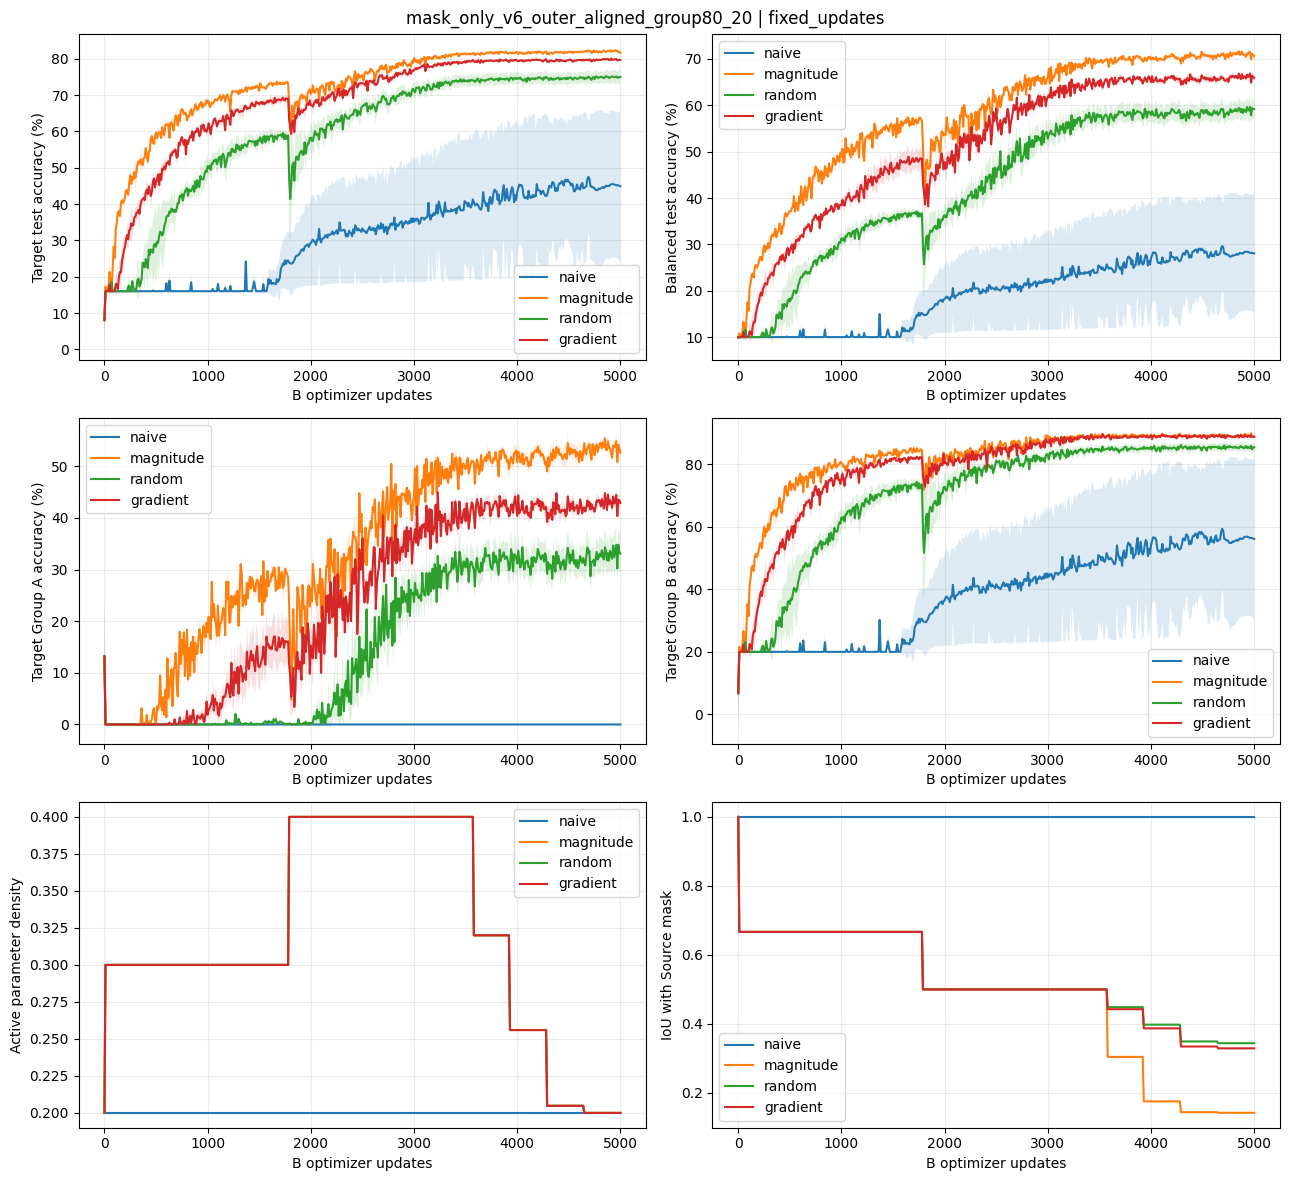

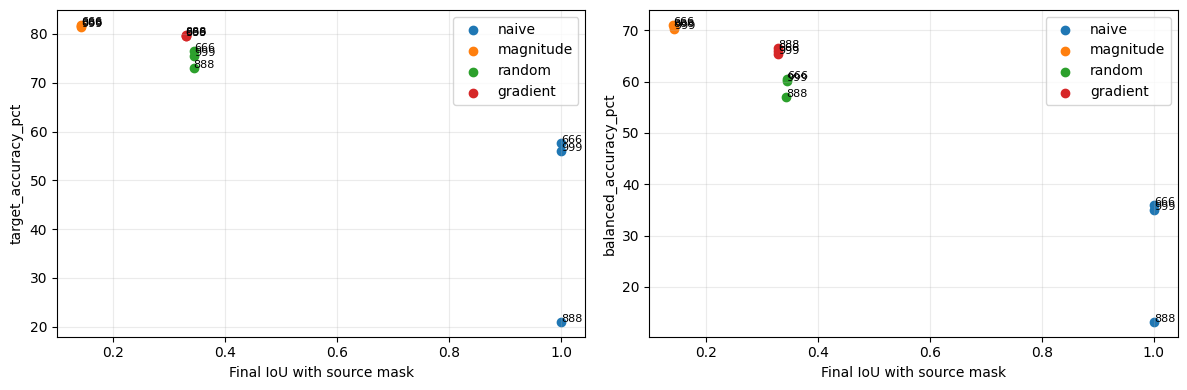

In [14]:
histories = []
for seed in TARGET_SEEDS:
    for method in METHODS:
        histories.append(pd.read_csv(RUN_DIR / f"seed_{seed}" / method / "metrics_every_10.csv"))
history = pd.concat(histories, ignore_index=True)
fig, axes = plt.subplots(3, 2, figsize=(13, 12))
metrics = [("target_test_accuracy_pct", "Target test accuracy (%)"),
           ("balanced_test_accuracy_pct", "Balanced test accuracy (%)"),
           ("test_group_A_accuracy_pct", "Target Group A accuracy (%)"),
           ("test_group_B_accuracy_pct", "Target Group B accuracy (%)"),
           ("density", "Active parameter density"), ("iou", "IoU with Source mask")]
for ax, (metric, title) in zip(axes.flat, metrics):
    for method in METHODS:
        stats = history[history.method == method].groupby("update")[metric].agg(["mean", "std"])
        x, mean, std = stats.index.to_numpy(), stats["mean"].to_numpy(), stats["std"].fillna(0).to_numpy()
        ax.plot(x, mean, label=method)
        ax.fill_between(x, mean - std, mean + std, alpha=.15)
    ax.set(xlabel="B optimizer updates", ylabel=title)
    ax.grid(alpha=.25)
    ax.legend()
fig.suptitle(f"{PROTOCOL} | {TARGET_BUDGET_MODE}")
fig.tight_layout()
save_figure_verified(fig, RUN_DIR / "learning_curves.png", dpi=150)
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["target_accuracy_pct", "balanced_accuracy_pct"]):
    for method in METHODS:
        rows = final_frame[final_frame.method == method]
        ax.scatter(rows.iou, rows[metric], label=method)
        for _, row in rows.iterrows():
            ax.annotate(str(row.seed), (row.iou, row[metric]), fontsize=8)
    ax.set(xlabel="Final IoU with source mask", ylabel=metric)
    ax.grid(alpha=.25)
    ax.legend()
fig.tight_layout()
save_figure_verified(fig, RUN_DIR / "mask_similarity_vs_accuracy.png", dpi=150)
plt.show()


## 13. Export
The ZIP contains reports, plots, split indices and masks; large checkpoints stay in the run folder.
Set `DOWNLOAD_REPORT=True` to download from Colab.


In [15]:
DOWNLOAD_REPORT = False
ensure_storage_ready()
archive_path = RUN_DIR.parent / f"{RUN_ID}_reports.zip"
local_archive = LOCAL_STAGING_ROOT / f"reports_{uuid.uuid4().hex}.zip"
included = []
for path in RUN_DIR.rglob("*"):
    if path.is_file() and path.name != "report_archive.json" and (path.suffix in {".json", ".jsonl", ".csv", ".png"}
                           or path.name in {"source_mask_only.pt", "final_mask.pt"}):
        included.append(path)
with zipfile.ZipFile(local_archive, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in tqdm(included, desc="Export report ZIP locally", unit="file"):
        archive.write(path, path.relative_to(RUN_DIR))
with zipfile.ZipFile(local_archive, "r") as archive:
    if archive.testzip() is not None:
        raise OSError(f"Report ZIP integrity check failed: {local_archive}")
archive_metadata = publish_local_file(local_archive, archive_path)
write_json(RUN_DIR / "report_archive.json", archive_metadata)
local_archive.unlink()
print("Verified reports:", archive_path)
print("Full run with checkpoints:", RUN_DIR)
if DOWNLOAD_REPORT:
    if IS_COLAB:
        from google.colab import files
        files.download(str(archive_path))
    else:
        print("Open the ZIP path above in your local file browser.")


Export report ZIP locally:   0%|          | 0/93 [00:00<?, ?file/s]

Verified reports: /content/data_transfer_learning/runs/mask_only_v6_outer_aligned_group80_20_fixed_updates_5000updates_outer_ratio_20261101T090212Z_4d5678_reports.zip
Full run with checkpoints: /content/data_transfer_learning/runs/mask_only_v6_outer_aligned_group80_20_fixed_updates_5000updates_outer_ratio_20261101T090212Z_4d5678


## Interpretation notes
- Repeats vary Target initialization; the Source mask and data split stay fixed.
- Equal update budgets do not imply equal compute.
- Gradient growth retains the outer implementation's zero inactive-gradient limitation.
